In [1]:
# Final notebook used for the project writing in Explorartory Data Analysis and Factor Analysis. Cluster Analysis in Notebook 2.

In [2]:
# Necessary Installs
!pip install factor_analyzer
!pip install pingouin pandas numpy
!pip install feature-engine


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Necessary Imports
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.rotator import Rotator
from factor_analyzer import FactorAnalyzer
import pingouin as pg
from numpy.linalg import inv
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from scipy.stats import zscore, pearsonr
import statsmodels.api as sm  
from feature_engine.outliers import Winsorizer
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import os

In [4]:

df = pd.read_excel(r"C:\Users\Pedro Salgado\Desktop\Nova IMS\Year 2\Semester 1\Data Analysis\Data Analysis PROJECT\merged project data.xlsx", sheet_name='project data')
df

,ID,Consumption_Footprint,Organic_Farming,Re_used_Material,Climate_Losses,Eco_Innovation,EGSS_Employment,Energy_Poverty,Env_Protection_Expenditure,Env_Taxes,Final_Energy_Consumption,Fossil_Fuel_Subsidies,EGSS_Output,Air_Pollution_Health_Impact,LULUCF_Emissions,Renewable_Energy_Share,Protected_Area_Share,GHG_Emissions,Waste_Generation,Gini_coefficient
0,Austria_2018,1.892036,24.08,11.8,37.791890,146.3,4.241939,1.6,3.1,5.77,100.951512,0.080430,4.57,69.861867,1831.306630,33.784,28.178180,99.774253,132.737670,26.8
1,Austria_2020,1.776125,25.69,11.4,39.397259,151.3,4.428170,1.5,3.0,5.40,94.323394,0.075277,4.70,44.202595,-949.871097,36.545,29.042595,93.792551,138.098642,27.0
2,Austria_2022,1.958326,25.69,12.4,50.520629,166.1,4.578288,2.7,3.2,4.37,95.581970,0.889807,4.84,46.337380,-206.472182,34.075,29.296838,92.331084,144.370979,27.8
3,Belgium_2018,1.719563,6.56,20.6,15.892110,91.2,1.644076,5.2,3.3,5.71,98.230608,0.792464,1.79,63.398693,-623.157510,9.472,14.344966,80.585878,105.985790,25.7
4,Belgium_2020,1.550222,7.25,22.9,17.818447,94.5,1.681996,4.1,3.3,5.50,90.342599,0.955979,1.97,42.108647,-398.639109,13.000,14.607227,73.446670,104.777975,25.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,Spain_2020,1.527788,9.98,9.3,23.491705,104.0,2.369679,10.9,1.7,4.67,76.100199,0.329626,2.71,49.936822,-51083.831336,21.220,28.085082,94.121190,75.516424,32.1
77,Spain_2022,1.980049,10.83,9.4,51.701113,109.5,2.635966,17.1,1.8,4.01,83.699601,0.854810,2.97,54.506186,-50620.843953,21.896,28.102400,101.968128,83.982391,32.0
78,Sweden_2018,1.679186,20.29,6.6,4.098194,155.0,2.859201,2.3,2.2,4.69,96.792137,0.138003,3.55,26.205694,-39780.815240,53.916,14.689867,72.235854,108.632921,27.0
79,Sweden_2020,1.523318,20.31,6.9,6.113909,160.9,2.949580,2.7,2.4,4.63,92.407780,0.080889,3.91,10.749564,-39351.305120,60.124,14.838799,64.578343,116.891192,26.9


In [5]:
# Quick look at structure
print(df.shape)      # (rows, columns)
print(df.columns)    # column names
df.head()

(81, 20)
Index(['ID', 'Consumption_Footprint', 'Organic_Farming', 'Re_used_Material',
       'Climate_Losses', 'Eco_Innovation', 'EGSS_Employment', 'Energy_Poverty',
       'Env_Protection_Expenditure', 'Env_Taxes', 'Final_Energy_Consumption',
       'Fossil_Fuel_Subsidies', 'EGSS_Output', 'Air_Pollution_Health_Impact',
       'LULUCF_Emissions', 'Renewable_Energy_Share', 'Protected_Area_Share',
       'GHG_Emissions', 'Waste_Generation', 'Gini_coefficient'],
      dtype='object')


,ID,Consumption_Footprint,Organic_Farming,Re_used_Material,Climate_Losses,Eco_Innovation,EGSS_Employment,Energy_Poverty,Env_Protection_Expenditure,Env_Taxes,Final_Energy_Consumption,Fossil_Fuel_Subsidies,EGSS_Output,Air_Pollution_Health_Impact,LULUCF_Emissions,Renewable_Energy_Share,Protected_Area_Share,GHG_Emissions,Waste_Generation,Gini_coefficient
0,Austria_2018,1.892036,24.08,11.8,37.791890,146.3,4.241939,1.6,3.1,5.77,100.951512,0.080430,4.57,69.861867,1831.306630,33.784,28.178180,99.774253,132.737670,26.8
1,Austria_2020,1.776125,25.69,11.4,39.397259,151.3,4.428170,1.5,3.0,5.40,94.323394,0.075277,4.70,44.202595,-949.871097,36.545,29.042595,93.792551,138.098642,27.0
2,Austria_2022,1.958326,25.69,12.4,50.520629,166.1,4.578288,2.7,3.2,4.37,95.581970,0.889807,4.84,46.337380,-206.472182,34.075,29.296838,92.331084,144.370979,27.8
3,Belgium_2018,1.719563,6.56,20.6,15.892110,91.2,1.644076,5.2,3.3,5.71,98.230608,0.792464,1.79,63.398693,-623.157510,9.472,14.344966,80.585878,105.985790,25.7
4,Belgium_2020,1.550222,7.25,22.9,17.818447,94.5,1.681996,4.1,3.3,5.50,90.342599,0.955979,1.97,42.108647,-398.639109,13.000,14.607227,73.446670,104.777975,25.4


In [6]:
features = df.columns.drop(["ID"]) 
summarytest = df[features].describe().T
summarytest

,count,mean,std,min,25%,50%,75%,max
Consumption_Footprint,81.0,1.811137,0.402809,1.001114,1.550222,1.755230,1.980049,2.900697
Organic_Farming,81.0,9.896173,6.388843,0.410000,4.630000,9.280000,14.470000,25.690000
Re_used_Material,81.0,9.661728,6.542965,1.500000,4.500000,8.300000,12.300000,27.200000
Climate_Losses,81.0,32.549925,28.780308,0.000000,8.756528,30.969546,43.206564,120.642617
Eco_Innovation,81.0,104.317284,34.270551,36.000000,80.300000,100.800000,124.200000,178.600000
EGSS_Employment,81.0,2.635880,1.092676,0.968208,1.849033,2.414555,2.949580,5.682435
Energy_Poverty,81.0,8.396296,7.370591,1.400000,3.000000,5.700000,10.000000,33.700000
Env_Protection_Expenditure,81.0,1.950617,0.620307,0.600000,1.600000,1.900000,2.300000,3.400000
Env_Taxes,81.0,6.927654,2.303521,3.050000,5.340000,6.720000,7.930000,15.320000
Final_Energy_Consumption,81.0,95.714734,13.513000,68.683728,88.608789,94.466901,99.186391,150.477554


In [7]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           81 non-null     object 
 1   Consumption_Footprint        81 non-null     float64
 2   Organic_Farming              81 non-null     float64
 3   Re_used_Material             81 non-null     float64
 4   Climate_Losses               81 non-null     float64
 5   Eco_Innovation               81 non-null     float64
 6   EGSS_Employment              81 non-null     float64
 7   Energy_Poverty               81 non-null     float64
 8   Env_Protection_Expenditure   81 non-null     float64
 9   Env_Taxes                    81 non-null     float64
 10  Final_Energy_Consumption     81 non-null     float64
 11  Fossil_Fuel_Subsidies        81 non-null     float64
 12  EGSS_Output                  81 non-null     float64
 13  Air_Pollution_Health_I

In [8]:

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Consumption_Footprint,81.0,1.811137,0.402809,1.001114,1.550222,1.755230,1.980049,2.900697
Organic_Farming,81.0,9.896173,6.388843,0.410000,4.630000,9.280000,14.470000,25.690000
Re_used_Material,81.0,9.661728,6.542965,1.500000,4.500000,8.300000,12.300000,27.200000
Climate_Losses,81.0,32.549925,28.780308,0.000000,8.756528,30.969546,43.206564,120.642617
Eco_Innovation,81.0,104.317284,34.270551,36.000000,80.300000,100.800000,124.200000,178.600000
EGSS_Employment,81.0,2.635880,1.092676,0.968208,1.849033,2.414555,2.949580,5.682435
Energy_Poverty,81.0,8.396296,7.370591,1.400000,3.000000,5.700000,10.000000,33.700000
Env_Protection_Expenditure,81.0,1.950617,0.620307,0.600000,1.600000,1.900000,2.300000,3.400000
Env_Taxes,81.0,6.927654,2.303521,3.050000,5.340000,6.720000,7.930000,15.320000
Final_Energy_Consumption,81.0,95.714734,13.513000,68.683728,88.608789,94.466901,99.186391,150.477554


In [9]:
# Check missing values
df.isnull().sum()

ID                             0
Consumption_Footprint          0
Organic_Farming                0
Re_used_Material               0
Climate_Losses                 0
Eco_Innovation                 0
EGSS_Employment                0
Energy_Poverty                 0
Env_Protection_Expenditure     0
Env_Taxes                      0
Final_Energy_Consumption       0
Fossil_Fuel_Subsidies          0
EGSS_Output                    0
Air_Pollution_Health_Impact    0
LULUCF_Emissions               0
Renewable_Energy_Share         0
Protected_Area_Share           0
GHG_Emissions                  0
Waste_Generation               0
Gini_coefficient               0
dtype: int64

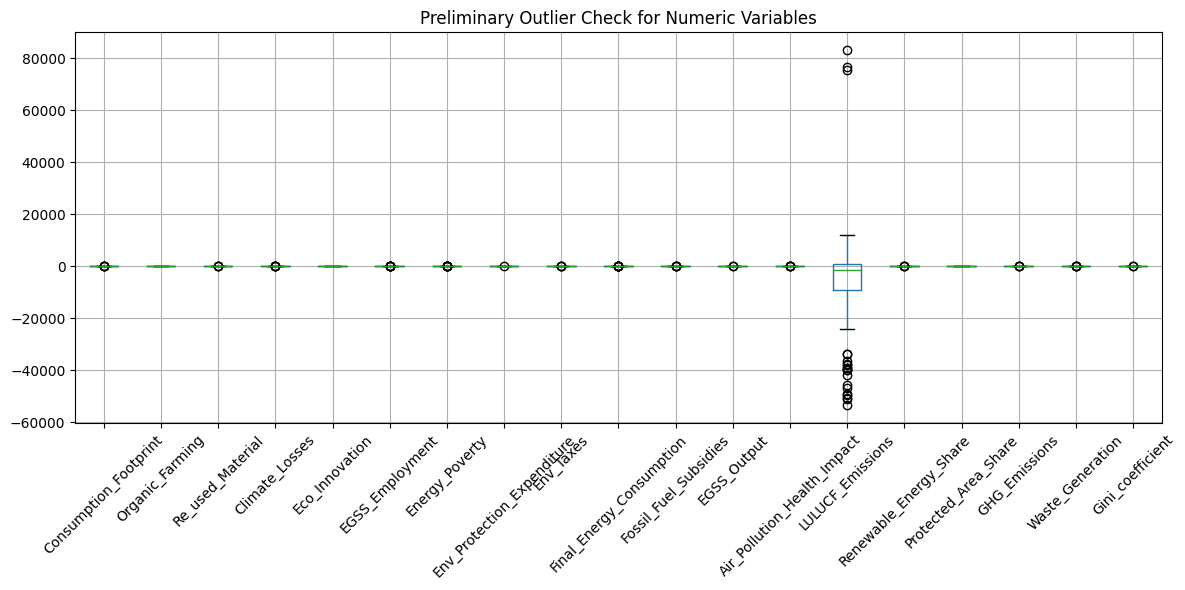

In [10]:
# Select only numeric columns 
numeric_df = df.select_dtypes(include=['float64', 'int64'])

# Quick overall boxplot to visualize potential outliers
plt.figure(figsize=(12, 6))
numeric_df.boxplot()
plt.xticks(rotation=45)
plt.title("Preliminary Outlier Check for Numeric Variables")
plt.tight_layout()
plt.show()

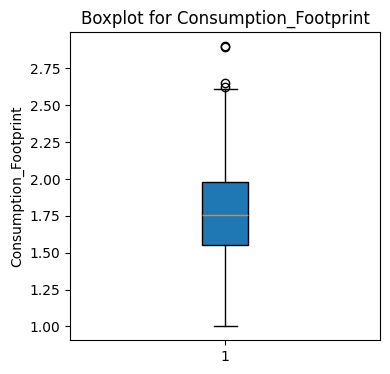

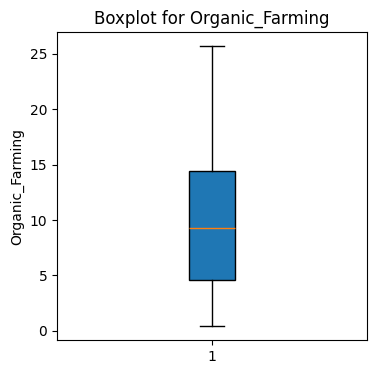

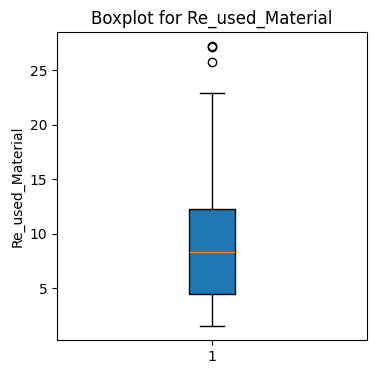

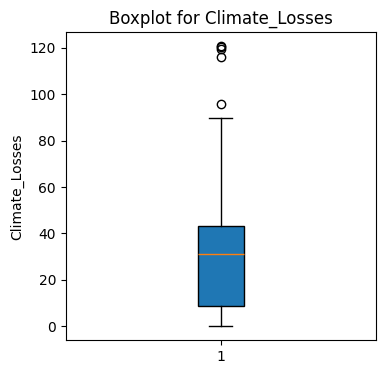

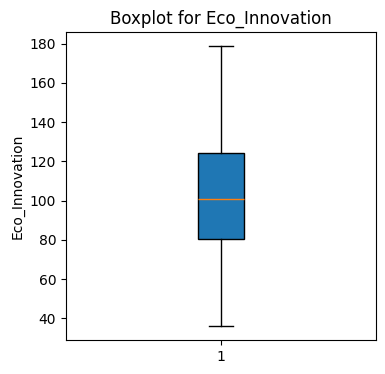

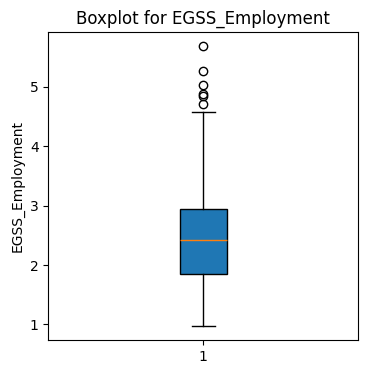

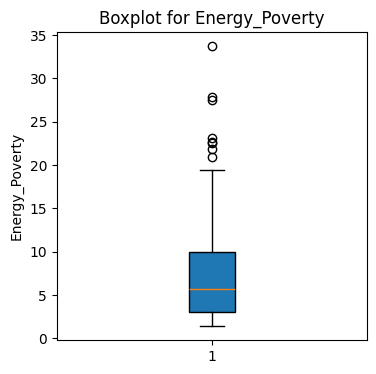

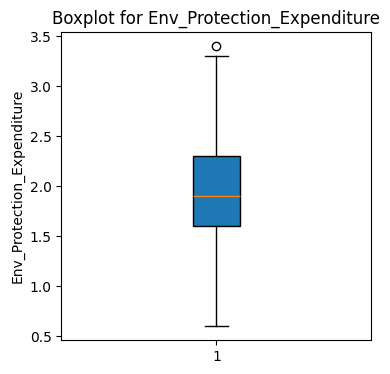

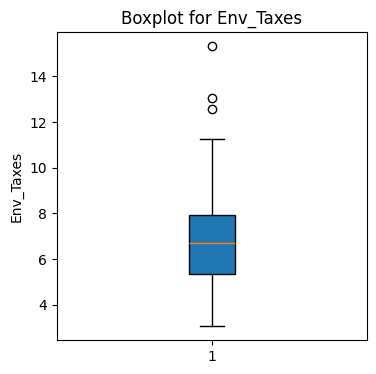

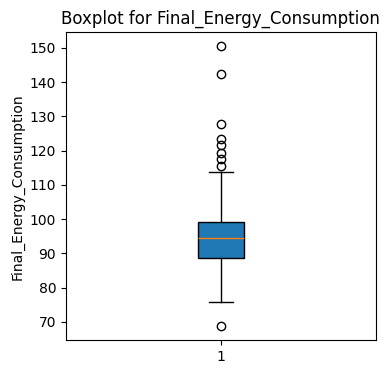

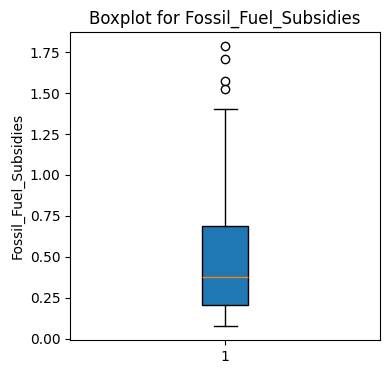

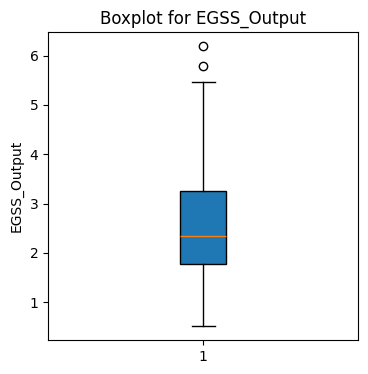

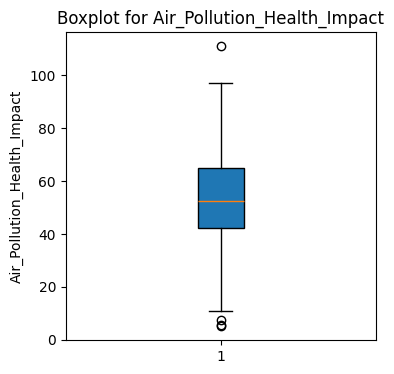

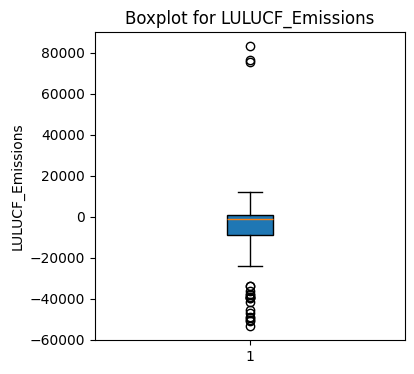

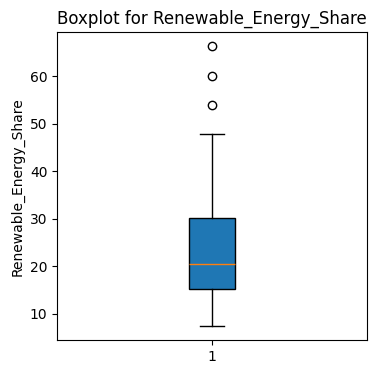

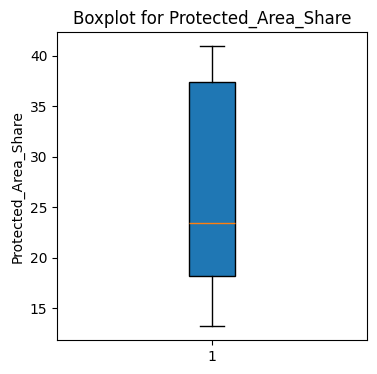

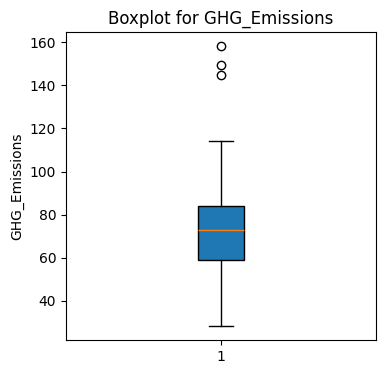

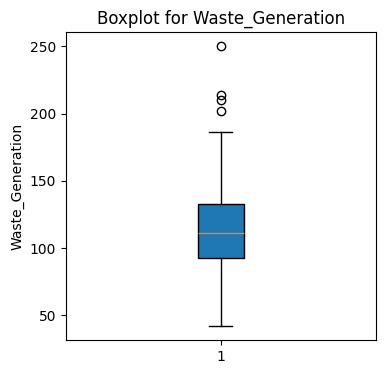

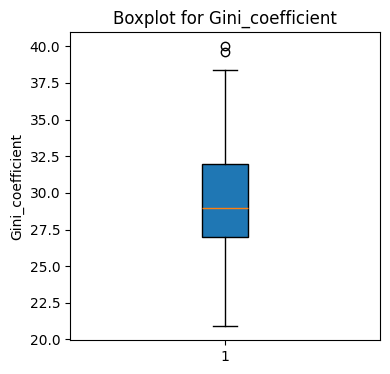

In [11]:
# Select numeric columns only 
numeric_df = df.select_dtypes(include=['float64', 'int64'])

for col in numeric_df.columns:
    plt.figure(figsize=(4, 4))
    plt.boxplot(numeric_df[col], vert=True, patch_artist=True)
    plt.title(f"Boxplot for {col}")
    plt.ylabel(col)
    plt.show()

In [12]:
# No outliers will be treated as they are all real data - as by the teacher's suggestion to cut 1/2 outliers maximum, and in preference to leave them untouched if real data.

In [13]:
# Below is a quote from a project that had 20 explaining a similar process as we will adopt.

"Outliers are observations that diverge considerably from the rest of the data. This can occur
because of measurement errors, uncommon characteristics of the observations, or natural
variability of a variable.
After seeing the summary statistics, we looked at the histograms and box plots of each
variable also given by the same ‘Summary Statistics’ task in SAS to view if there are any 1-
dimensional outliers. There were 3 outliers in the variable ‘Pa_EPO’ for Luxembourg_2013,
Luxembourg_2016, and Luxembourg_2019, but we decided that this values are well
measured and significantly important for our analysis as they will highlight Luxembourg’s
strengths in Innovation and R&D efficiency, so we kept the observations. There was also an
outlier in variable ‘Ent_TDS’ for Austria_2013, one outlier in variable ‘AInt_35_44’ for
Romania_2013, one outlier in ‘AInt_25_34’ for Romania_2013, two outliers in ‘AInt_16_24’
for Bulgaria_2013 and Romania_2013, but we decided as before that is was well measured
and important to understand the countries’ performance in Industry 4.0. Although some
countries can be considered outliers in some few variables, there were none to be taken out
of the analysis, as this will enrich our analysis. So no countries taken out based on one-
dimensional outliers’ analysis.
01 PROPOSAL
Treating Outliers
As seen before there were some outliers, however this outliers were not significant, and we
considered them all well measured, meaning there were no measurement errors."

In [14]:

numeric_df = df.select_dtypes(include=['float64', 'int64'])
skew_vals = numeric_df.skew().sort_values(ascending=False)
print(skew_vals)

Final_Energy_Consumption       1.539918
Energy_Poverty                 1.450807
Climate_Losses                 1.432474
Fossil_Fuel_Subsidies          1.365974
Renewable_Energy_Share         1.300064
Env_Taxes                      1.070103
GHG_Emissions                  1.012701
LULUCF_Emissions               0.956112
Re_used_Material               0.947902
EGSS_Employment                0.945317
Waste_Generation               0.930097
EGSS_Output                    0.778401
Organic_Farming                0.708144
Consumption_Footprint          0.674705
Eco_Innovation                 0.374734
Gini_coefficient               0.328588
Env_Protection_Expenditure     0.287069
Protected_Area_Share           0.170328
Air_Pollution_Health_Impact   -0.100505
dtype: float64


In [15]:
# Standardize the data

scaler = StandardScaler()
data_standardizedtest = scaler.fit_transform(df[features]) 

data_standardizedtest = pd.DataFrame(data_standardizedtest, columns=features) 

data_standardizedtest

,Consumption_Footprint,Organic_Farming,Re_used_Material,Climate_Losses,Eco_Innovation,EGSS_Employment,Energy_Poverty,Env_Protection_Expenditure,Env_Taxes,Final_Energy_Consumption,Fossil_Fuel_Subsidies,EGSS_Output,Air_Pollution_Health_Impact,LULUCF_Emissions,Renewable_Energy_Share,Protected_Area_Share,GHG_Emissions,Waste_Generation,Gini_coefficient
0,0.202087,2.233926,0.328841,0.183272,1.232670,1.478999,-0.927828,1.864470,-0.505690,0.389951,-1.037621,1.683432,0.892414,0.370161,0.830887,0.169536,1.060420,0.417551,-0.659501
1,-0.087464,2.487498,0.267326,0.239400,1.379477,1.650496,-0.941480,1.702255,-0.667314,-0.103605,-1.049995,1.793501,-0.383066,0.255707,1.062813,0.263035,0.814506,0.557300,-0.609033
2,0.367681,2.487498,0.421114,0.628300,1.814026,1.788738,-0.777656,2.026685,-1.117242,-0.009886,0.905798,1.912036,-0.276949,0.286300,0.855331,0.290535,0.754424,0.720806,-0.407164
3,-0.228755,-0.525441,1.682177,-0.582398,-0.385142,-0.913339,-0.436357,2.188900,-0.531899,0.187342,0.672065,-0.670342,0.571140,0.269152,-1.211335,-1.326727,0.271566,-0.279810,-0.937070
4,-0.651775,-0.416767,2.035889,-0.515049,-0.288249,-0.878419,-0.586529,2.188900,-0.623632,-0.400030,1.064686,-0.517939,-0.487153,0.278392,-0.914981,-1.298360,-0.021935,-0.311295,-1.012771
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,-0.707816,0.013203,-0.055630,-0.316698,-0.009316,-0.245141,0.341805,-0.406539,-0.986195,-1.460575,-0.439270,0.108605,-0.098027,-1.807455,-0.224496,0.159466,0.828017,-1.074077,0.677881
77,0.421947,0.147076,-0.040251,0.669573,0.152172,0.000079,1.188227,-0.244324,-1.274498,-0.894694,0.821767,0.328742,0.129109,-1.788402,-0.167712,0.161339,1.150613,-0.853389,0.652647
78,-0.329620,1.637008,-0.470858,-0.994743,1.488114,0.205653,-0.832264,0.404536,-0.977458,0.080228,-0.899382,0.819817,-1.277662,-1.342302,2.521987,-1.289421,-0.071713,-0.210805,-0.609033
79,-0.718982,1.640158,-0.424721,-0.924268,1.661346,0.288882,-0.777656,0.728966,-1.003668,-0.246249,-1.036519,1.124623,-2.045961,-1.324627,3.043463,-1.273312,-0.386521,0.004469,-0.634267


In [16]:
summary_stantest = data_standardizedtest[features].describe().T
summary_stantest

,count,mean,std,min,25%,50%,75%,max
Consumption_Footprint,81.0,-4.249002e-17,1.006231,-2.023467,-0.651775,-0.139659,0.421947,2.721758
Organic_Farming,81.0,-3.015421e-16,1.006231,-1.494054,-0.829412,-0.097046,0.720369,2.487498
Re_used_Material,81.0,-1.027984e-16,1.006231,-1.255177,-0.793813,-0.209418,0.405735,2.697179
Climate_Losses,81.0,2.521988e-16,1.006231,-1.138026,-0.831876,-0.055254,0.372582,3.079938
Eco_Innovation,81.0,5.235867e-16,1.006231,-2.005890,-0.705181,-0.103272,0.583784,2.181043
EGSS_Employment,81.0,3.221017e-17,1.006231,-1.535736,-0.724596,-0.203815,0.288882,2.805532
Energy_Poverty,81.0,1.110223e-16,1.006231,-0.955132,-0.736701,-0.368097,0.218937,3.454453
Env_Protection_Expenditure,81.0,7.346661e-16,1.006231,-2.190903,-0.568754,-0.082109,0.566751,2.351115
Env_Taxes,81.0,-5.372931e-16,1.006231,-1.693848,-0.693524,-0.090708,0.437847,3.665968
Final_Energy_Consumption,81.0,1.442947e-15,1.006231,-2.012834,-0.529136,-0.092918,0.258513,4.077853


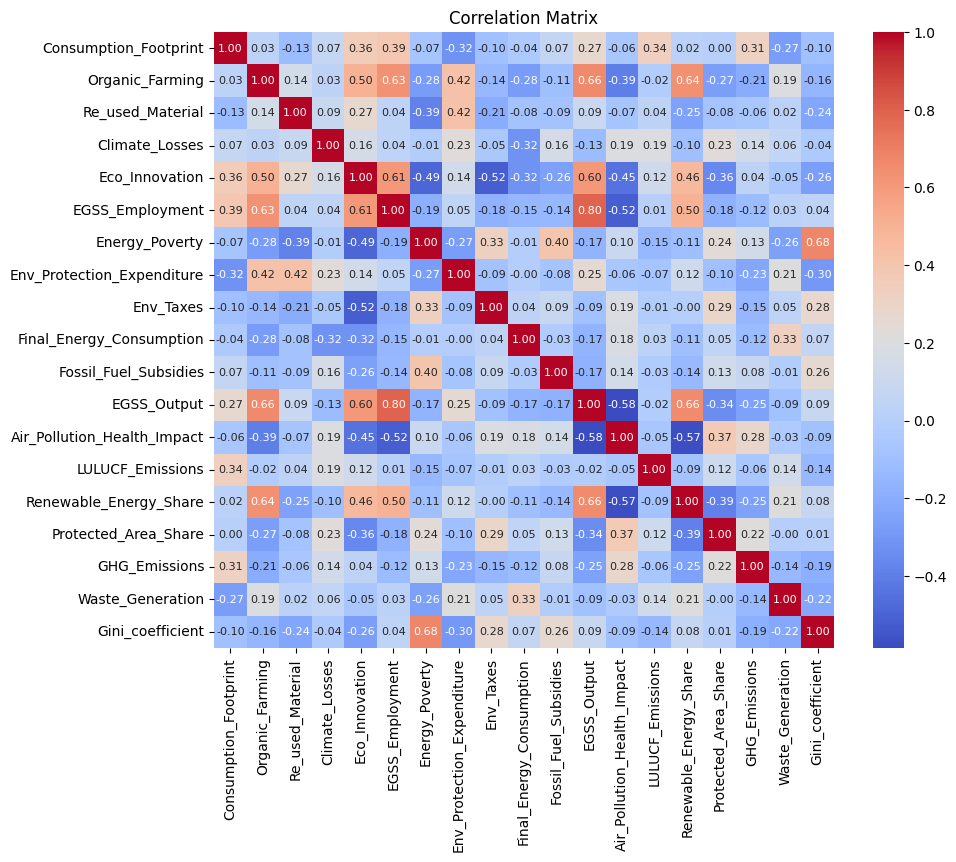

In [17]:
# correlations

corr_matrixtest = data_standardizedtest.corr() 

plt.figure(figsize=(10, 8)) 
sns.heatmap(corr_matrixtest, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 8}) 
plt.title('Correlation Matrix')
plt.show()

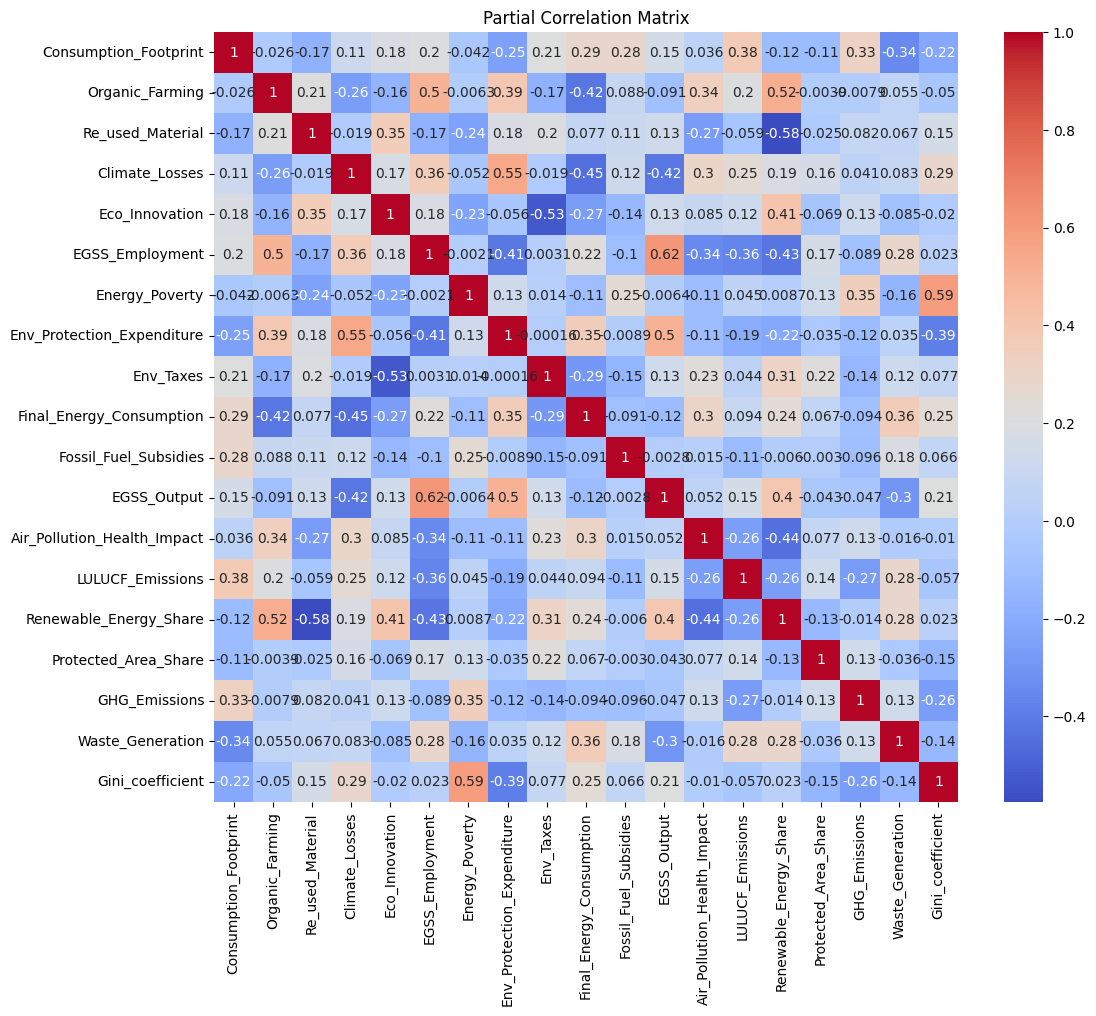

In [18]:
#Partial correlations

partial_corr_matrix = pd.DataFrame(index=features, columns=features)

for var1 in features:
    for var2 in features:
        if var1 == var2:
            partial_corr_matrix.loc[var1, var2] = 1.0
        else:
            covariates = [col for col in features if col not in [var1, var2]]
            result = pg.partial_corr(data=data_standardizedtest, x=var1, y=var2, covar=covariates)
            partial_corr_matrix.loc[var1, var2] = result['r'].values[0]

partial_corr_matrix = partial_corr_matrix.astype(float)

plt.figure(figsize=(12, 10))
sns.heatmap(partial_corr_matrix, annot=True, cmap='coolwarm')
plt.title('Partial Correlation Matrix')
plt.show()

In [19]:


#Overall KMO
kmo_all, kmo_model = calculate_kmo(data_standardizedtest) 
print(f"KMO Overall: {kmo_model:.3f}")

#Individual KMO
kmo_all_series = pd.Series(kmo_all, index=features)
print("\nKMO per variable:")
print(kmo_all_series.round(3))

KMO Overall: 0.557

KMO per variable:
Consumption_Footprint          0.483
Organic_Farming                0.649
Re_used_Material               0.435
Climate_Losses                 0.242
Eco_Innovation                 0.736
EGSS_Employment                0.578
Energy_Poverty                 0.674
Env_Protection_Expenditure     0.395
Env_Taxes                      0.490
Final_Energy_Consumption       0.303
Fossil_Fuel_Subsidies          0.615
EGSS_Output                    0.684
Air_Pollution_Health_Impact    0.661
LULUCF_Emissions               0.248
Renewable_Energy_Share         0.543
Protected_Area_Share           0.803
GHG_Emissions                  0.544
Waste_Generation               0.400
Gini_coefficient               0.527
dtype: float64


In [20]:
# Very low, with a lot of negative variables. Reduce dataset to 10 with the best KMO

In [21]:
# Initialize variables
current_cols = list(data_standardizedtest.columns)
best_kmo_score = 0
best_combination = []

print(f"Starting iteration with {len(current_cols)} variables...\n")

while len(current_cols) >= 10:
    subset_df = data_standardizedtest[current_cols]
    kmo_per_var, kmo_total = calculate_kmo(subset_df)

    if kmo_total > best_kmo_score:
        best_kmo_score = kmo_total
        best_combination = list(current_cols)

    print(f"Count: {len(current_cols)} | Overall KMO: {kmo_total:.4f} | Removed previous lowest")

    variable_scores = dict(zip(current_cols, kmo_per_var))
    worst_variable = min(variable_scores, key=variable_scores.get)
    current_cols.remove(worst_variable)

print("-" * 60)
print(f"SEARCH COMPLETE.")
print(f"Highest KMO Found: {best_kmo_score:.4f}")
print(f"Number of Variables: {len(best_combination)}")
print("\nOptimal Variable Combination:")
print(best_combination)

Starting iteration with 19 variables...

Count: 19 | Overall KMO: 0.5571 | Removed previous lowest
Count: 18 | Overall KMO: 0.6053 | Removed previous lowest
Count: 17 | Overall KMO: 0.6302 | Removed previous lowest
Count: 16 | Overall KMO: 0.6650 | Removed previous lowest
Count: 15 | Overall KMO: 0.6811 | Removed previous lowest
Count: 14 | Overall KMO: 0.7228 | Removed previous lowest
Count: 13 | Overall KMO: 0.7439 | Removed previous lowest
Count: 12 | Overall KMO: 0.7538 | Removed previous lowest
Count: 11 | Overall KMO: 0.7780 | Removed previous lowest
Count: 10 | Overall KMO: 0.8000 | Removed previous lowest
------------------------------------------------------------
SEARCH COMPLETE.
Highest KMO Found: 0.8000
Number of Variables: 10

Optimal Variable Combination:
['Organic_Farming', 'Eco_Innovation', 'EGSS_Employment', 'Energy_Poverty', 'Fossil_Fuel_Subsidies', 'EGSS_Output', 'Air_Pollution_Health_Impact', 'Renewable_Energy_Share', 'Protected_Area_Share', 'Gini_coefficient']


In [22]:
features_subset = [
    'Organic_Farming', 'Eco_Innovation', 'EGSS_Employment',
    'Energy_Poverty', 'Fossil_Fuel_Subsidies', 'EGSS_Output',
    'Air_Pollution_Health_Impact', 'Renewable_Energy_Share',
    'Protected_Area_Share', 'Gini_coefficient'
]

df_subset = data_standardizedtest[features_subset]

kmo_all, kmo_model = calculate_kmo(df_subset)
print(f"KMO Overall: {kmo_model:.3f}")

kmo_all_series = pd.Series(kmo_all, index=features_subset)
print("\nKMO per variable:")
print(kmo_all_series.round(3))

KMO Overall: 0.800

KMO per variable:
Organic_Farming                0.821
Eco_Innovation                 0.891
EGSS_Employment                0.779
Energy_Poverty                 0.670
Fossil_Fuel_Subsidies          0.802
EGSS_Output                    0.847
Air_Pollution_Health_Impact    0.885
Renewable_Energy_Share         0.816
Protected_Area_Share           0.776
Gini_coefficient               0.563
dtype: float64


In [23]:
# this is the best combination avaliable for the highest kmo, .800 is great

In [24]:
# check descriptive statistics again

In [25]:
summary_df_subset = df_subset.describe().T
display(summary_df_subset)

,count,mean,std,min,25%,50%,75%,max
Organic_Farming,81.0,-3.015421e-16,1.006231,-1.494054,-0.829412,-0.097046,0.720369,2.487498
Eco_Innovation,81.0,5.235867e-16,1.006231,-2.005890,-0.705181,-0.103272,0.583784,2.181043
EGSS_Employment,81.0,3.221017e-17,1.006231,-1.535736,-0.724596,-0.203815,0.288882,2.805532
Energy_Poverty,81.0,1.110223e-16,1.006231,-0.955132,-0.736701,-0.368097,0.218937,3.454453
Fossil_Fuel_Subsidies,81.0,6.716164e-17,1.006231,-1.049995,-0.735006,-0.328395,0.423686,3.058001
EGSS_Output,81.0,1.206168e-16,1.006231,-1.754093,-0.678808,-0.196200,0.574280,3.055056
Air_Pollution_Health_Impact,81.0,-3.563679e-16,1.006231,-2.328160,-0.472593,0.034868,0.654553,2.938485
Renewable_Energy_Share,81.0,-9.868649e-17,1.006231,-1.385888,-0.735304,-0.289597,0.518825,3.561158
Protected_Area_Share,81.0,-2.247859e-16,1.006231,-1.452119,-0.915345,-0.342511,1.168743,1.548634
Gini_coefficient,81.0,3.303256e-16,1.006231,-2.148283,-0.609033,-0.104361,0.652647,2.671335


In [26]:
# ready to perfom analysis

In [27]:
# PCA is not the right analysis for the project. still performed below, but factor analysis is the chosen 

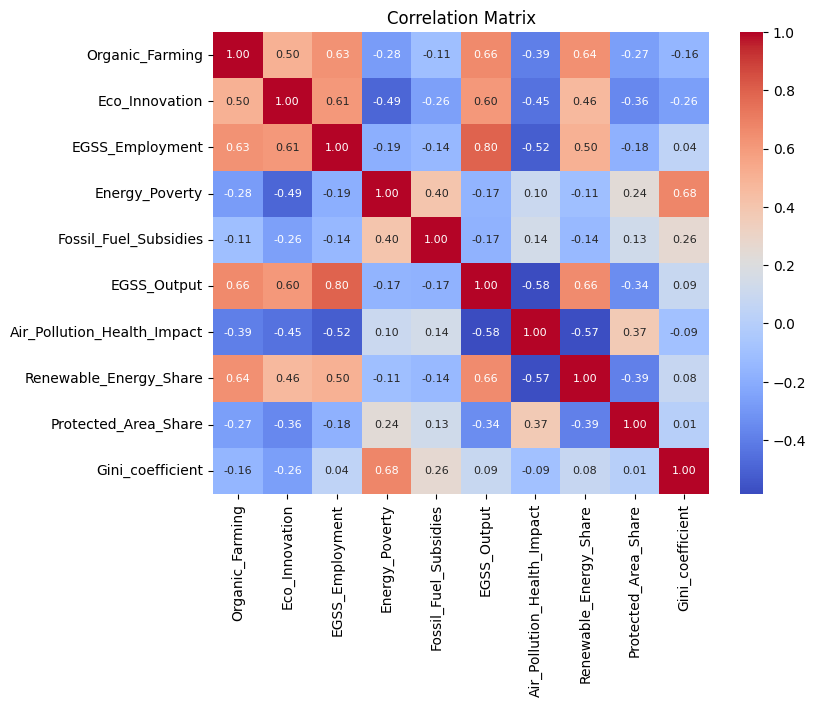

In [28]:
df_scaled = df_subset

newcorr_matrixtest = df_scaled.corr() 

plt.figure(figsize=(8, 6)) 
sns.heatmap(newcorr_matrixtest, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 8}) 
plt.title('Correlation Matrix')
plt.show()

In [29]:
# PCA
pca = PCA()
X_pca = pca.fit_transform(df_scaled)

In [30]:
# Kaiser Criterion
eigenvalues = pca.explained_variance_
print("Eigenvalues of PCA Components:")
print(eigenvalues)

Eigenvalues of PCA Components:
[4.32205555 1.95145444 0.94627422 0.81245091 0.58217697 0.51401902
 0.3455784  0.26032752 0.22566183 0.16500115]


In [31]:
# Pearson Criterion
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)
print("Cumulative Variance:")
print(cumulative_variance)

Cumulative Variance:
[0.42686968 0.61960592 0.71306511 0.79330717 0.85080613 0.90157344
 0.93570464 0.961416   0.98370359 1.        ]


C:\Users\Pedro Salgado\AppData\Local\Temp\ipykernel_18576\4080139088.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


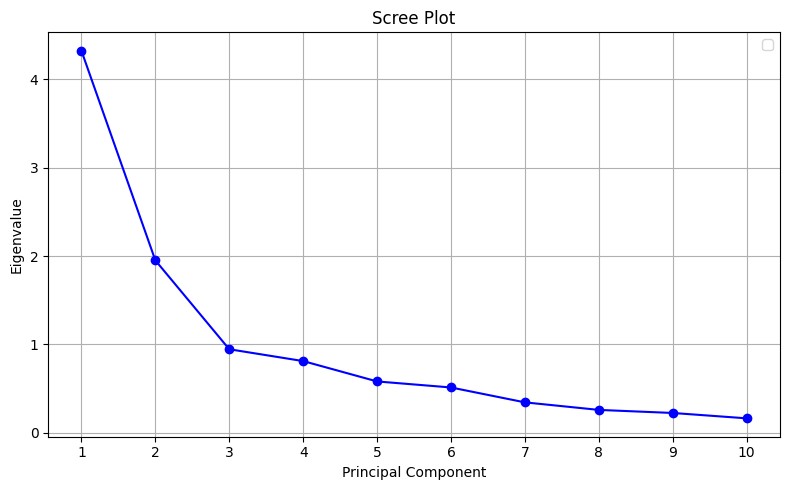

In [32]:
# Scree Plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), pca.explained_variance_, marker='o', linestyle='-', color='blue')
plt.title("Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.xticks(range(1, len(eigenvalues)+1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\Pedro Salgado\AppData\Local\Temp\ipykernel_18576\2914444951.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


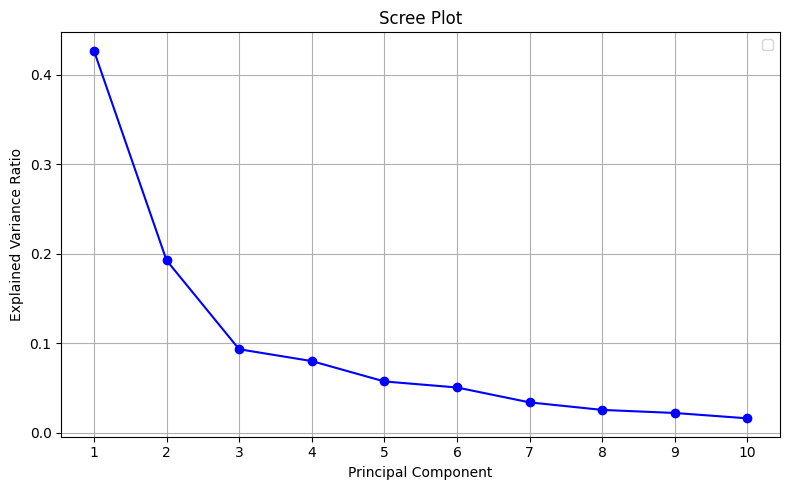

In [33]:
# Explained Variance Ratio Graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), pca.explained_variance_ratio_, marker='o', linestyle='-', color='blue')
plt.title("Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, len(eigenvalues)+1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
# kaiser = 2 components
# pearson = 4 components
# scree = 3  components

In [35]:
# PCA with 3 components
pca = PCA(n_components=3) 
X_pca = pca.fit_transform(df_scaled)

In [36]:
# Eigenvectors
eigenvecs = pd.DataFrame(
    pca.components_.T,
    columns=["PC1","PC2","PC3"],
    index=df_scaled.columns
)

eigenvecs

,PC1,PC2,PC3
Organic_Farming,0.378332,0.033420,0.299095
Eco_Innovation,0.382388,-0.163798,0.064422
EGSS_Employment,0.389113,0.137516,0.359716
Energy_Poverty,-0.206820,0.578525,0.007754
Fossil_Fuel_Subsidies,-0.152560,0.354426,0.263368
EGSS_Output,0.419754,0.181355,0.140255
Air_Pollution_Health_Impact,-0.338943,-0.191408,0.235387
Renewable_Energy_Share,0.372694,0.195143,-0.110892
Protected_Area_Share,-0.241674,0.002112,0.768388
Gini_coefficient,-0.069306,0.620663,-0.172565


In [37]:
# Loadings
eigenvalues = pca.explained_variance_
sqrt_eigenvals = np.sqrt(eigenvalues)
loadings = eigenvecs.multiply(sqrt_eigenvals, axis=1 )
print("PCA Loadings")
loadings

PCA Loadings


,PC1,PC2,PC3
Organic_Farming,0.786535,0.046685,0.290949
Eco_Innovation,0.794967,-0.228817,0.062668
EGSS_Employment,0.808949,0.192102,0.349919
Energy_Poverty,-0.429970,0.808167,0.007543
Fossil_Fuel_Subsidies,-0.317166,0.495114,0.256196
EGSS_Output,0.872651,0.253342,0.136436
Air_Pollution_Health_Impact,-0.704648,-0.267386,0.228976
Renewable_Energy_Share,0.774814,0.272604,-0.107872
Protected_Area_Share,-0.502429,0.002950,0.747462
Gini_coefficient,-0.144084,0.867031,-0.167865


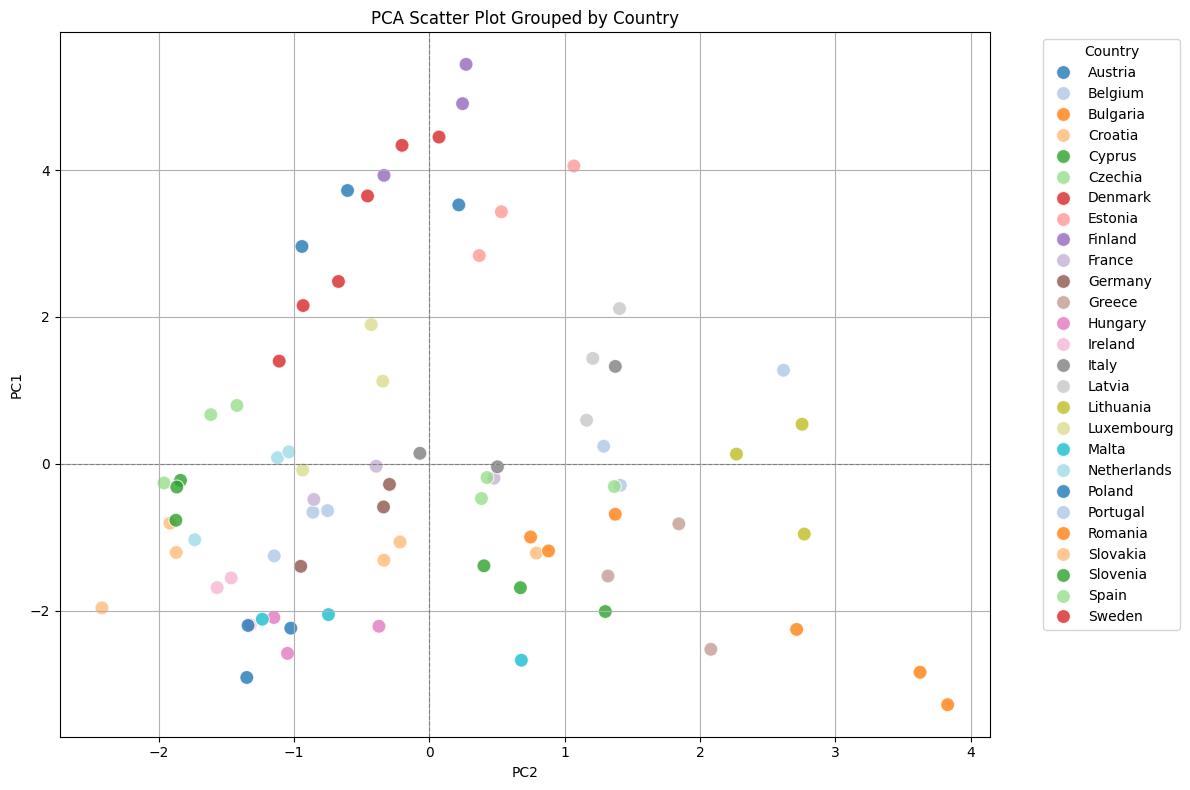

In [38]:
def highlight_strongest_loading(s):
    is_max = (s.abs() == s.abs().max())
    return ['background-color: lightgreen' if v else '' for v in is_max]

pc_scores_country = pd.DataFrame(X_pca, columns=["PC1","PC2","PC3"])
pc_scores_country['Country'] = df['ID'].str.split('_').str[0]

plt.figure(figsize=(12, 8)) 
sns.scatterplot(data=pc_scores_country, x="PC2", y="PC1", hue="Country", palette='tab20', s=100, alpha=0.8)

plt.title('PCA Scatter Plot Grouped by Country')
plt.xlabel('PC2')
plt.ylabel('PC1')
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')
plt.grid(True)
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

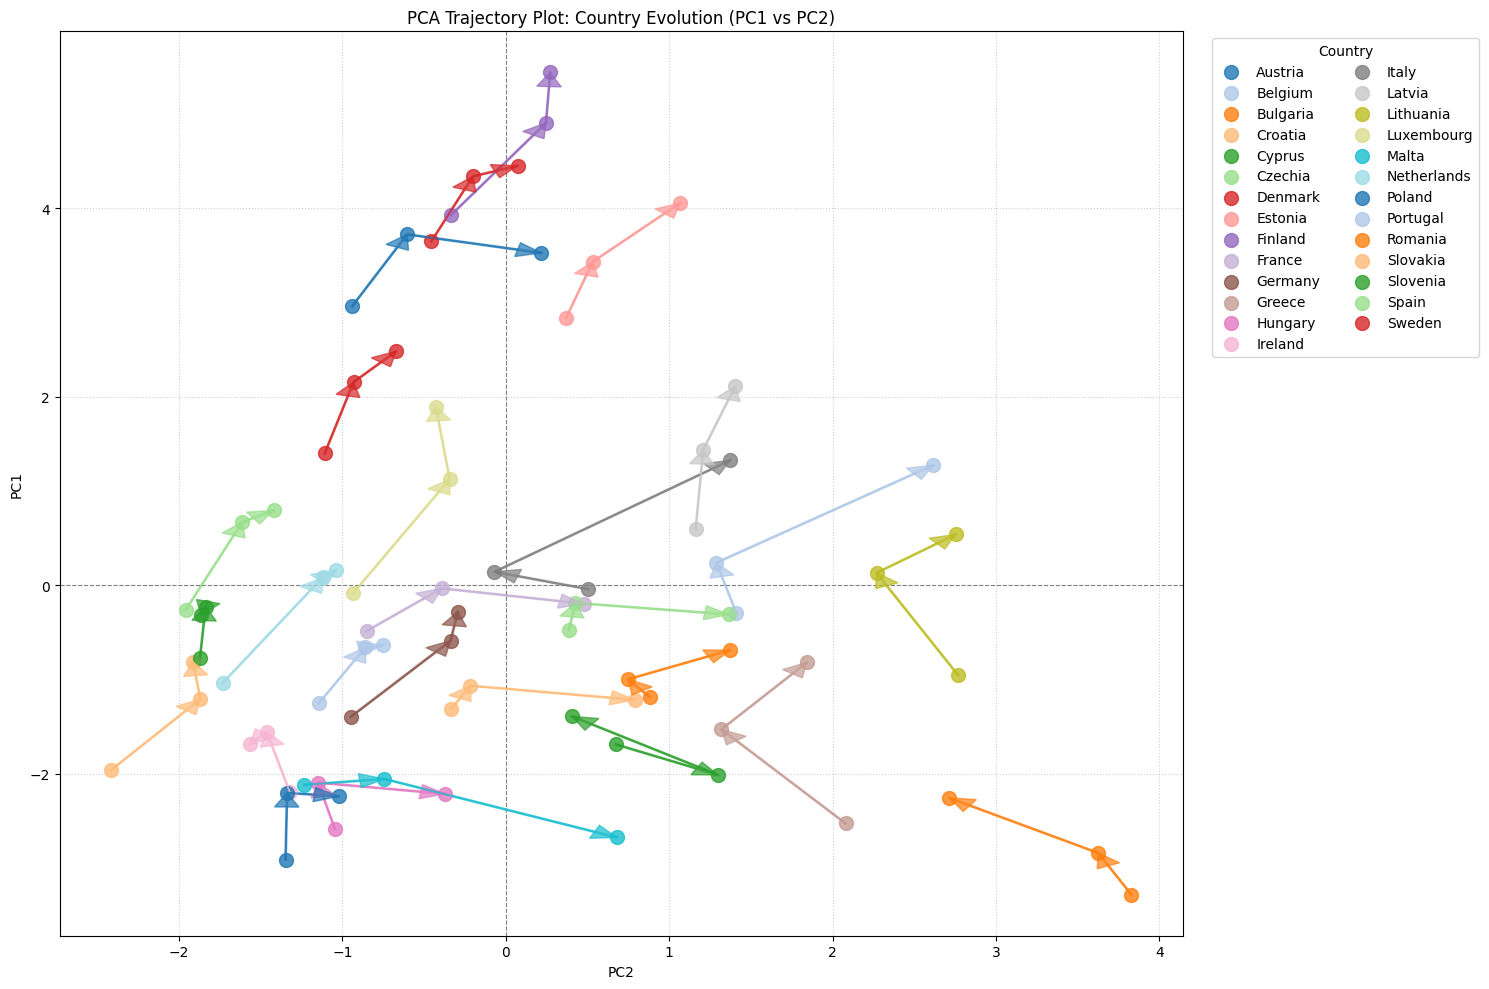

In [39]:
pc_scores_trajectory = pd.DataFrame(X_pca, columns=["PC1","PC2","PC3"])
pc_scores_trajectory['Country'] = df['ID'].str.split('_').str[0]
pc_scores_trajectory['Year'] = df['ID'].str.split('_').str[1].astype(int)

pc_scores_trajectory_sorted = pc_scores_trajectory.sort_values(by=['Country', 'Year'])

plt.figure(figsize=(15, 10))

unique_countries = pc_scores_trajectory_sorted['Country'].unique()
palette = sns.color_palette("tab20", n_colors=len(unique_countries))
country_color_map = {country: palette[i] for i, country in enumerate(unique_countries)}

for country in unique_countries:
    country_data = pc_scores_trajectory_sorted[pc_scores_trajectory_sorted['Country'] == country]
    color = country_color_map[country]

    plt.scatter(
        country_data['PC2'], country_data['PC1'],
        color=color, s=100, alpha=0.8, zorder=5, label=country
    )

    plt.plot(
        country_data['PC2'], country_data['PC1'],
        color=color, linestyle='-', linewidth=2, alpha=0.7
    )

    if len(country_data) > 1:
        for i in range(len(country_data) - 1):
            x1, y1 = country_data.iloc[i]['PC2'], country_data.iloc[i]['PC1']
            x2, y2 = country_data.iloc[i+1]['PC2'], country_data.iloc[i+1]['PC1']
            dx, dy = x2 - x1, y2 - y1
            plt.arrow(x1, y1, dx, dy, head_width=0.15, head_length=0.15, fc=color, ec=color, length_includes_head=True, alpha=0.7, zorder=6)

plt.title('PCA Trajectory Plot: Country Evolution (PC1 vs PC2)')
plt.xlabel('PC2')
plt.ylabel('PC1')
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Country', bbox_to_anchor=(1.02, 1), loc='upper left', ncol=2)
plt.tight_layout()
plt.show()

In [40]:
# Moving to Factor Analysis

In [41]:
df_final = df_scaled.copy()

In [42]:
# Initialize FA
fa = FactorAnalyzer()
fa.fit(df_scaled)

c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,3
,rotation,'promax'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [43]:
# Kaiser Criterion
eigenvalues, _ = fa.get_eigenvalues()
print("Eigenvalues:\n", eigenvalues)

Eigenvalues:
 [4.26869684 1.92736241 0.93459182 0.80242065 0.5749896  0.5076731
 0.341312   0.2571136  0.22287588 0.1629641 ]


In [44]:
# Pearson Criterion
variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_variance = np.cumsum(variance_ratio)
print("Cumulative variance:")
print(cumulative_variance)

Cumulative variance:
[0.42686968 0.61960592 0.71306511 0.79330717 0.85080613 0.90157344
 0.93570464 0.961416   0.98370359 1.        ]


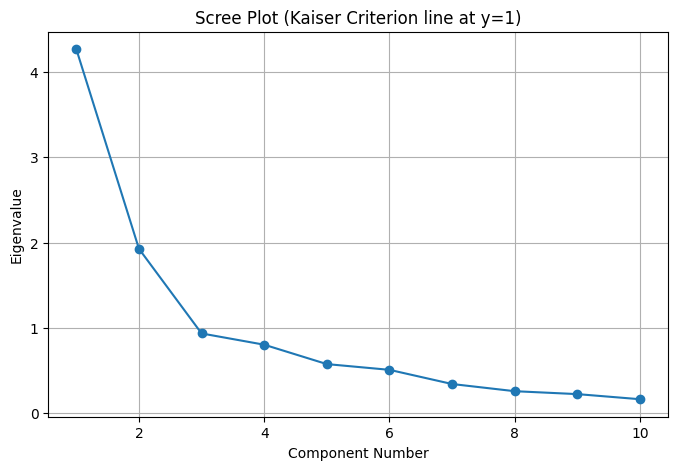

In [45]:
# Scree Plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, marker='o')
plt.title('Scree Plot (Kaiser Criterion line at y=1)')
plt.xlabel('Component Number')
plt.ylabel('Eigenvalue')
plt.grid(True)
plt.show()

In [46]:
# kaiser = 2 components
# pearson = 4 components
# scree = 3  components

In [47]:
# Calculate RMSR for 2 factors
fa_2 = FactorAnalyzer(n_factors=2, rotation=None, method="minres")
fa_2.fit(df_final)

loadings_2 = fa_2.loadings_
reconstructed_corr_2 = np.dot(loadings_2, loadings_2.T)
residuals_2 = newcorr_matrixtest.values - reconstructed_corr_2

mask = ~np.eye(residuals_2.shape[0], dtype=bool)
rmsr_2 = np.sqrt(np.mean(residuals_2[mask]**2))

print(f"RMSR for 2 factors: {rmsr_2:.3f}")

RMSR for 2 factors: 0.050


c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [48]:
#RMSR for 3 factors

# Ensure 'fa' is the FactorAnalyzer for 3 factors (unrotated) that was previously fitted
# This fa object was initialized in cell oArb02VGzu7G
# fa.fit(df_final) is already run there

reconstructed_corr = np.dot(fa.loadings_, fa.loadings_.T)

residuals = newcorr_matrixtest.values - reconstructed_corr

mask = ~np.eye(residuals.shape[0], dtype=bool)
rmsr_3 = np.sqrt(np.mean(residuals[mask]**2))

print(f"RMSR for 3 factors: {rmsr_3:.3f}")

RMSR for 3 factors: 0.220


In [49]:
from factor_analyzer import FactorAnalyzer

# Calculate RMSR for 4 factors
fa_4 = FactorAnalyzer(n_factors=4, rotation=None, method="minres")
fa_4.fit(df_final)

loadings_4 = fa_4.loadings_
reconstructed_corr_4 = np.dot(loadings_4, loadings_4.T)
residuals_4 = newcorr_matrixtest.values - reconstructed_corr_4

mask = ~np.eye(residuals_4.shape[0], dtype=bool)
rmsr_4 = np.sqrt(np.mean(residuals_4[mask]**2))

print(f"RMSR for 4 factors: {rmsr_4:.3f}")

RMSR for 4 factors: 0.013


c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [50]:
# Factor Analysis with 2 factors
fa_2_factors = FactorAnalyzer(n_factors=2, rotation='varimax', method='minres')
fa_2_factors.fit(df_scaled)
communalities_2 = fa_2_factors.get_communalities()
print("\nFinal Communality Estimates (2 Factors):\n", pd.Series(communalities_2, index=df_scaled.columns))
print(f"Total Communality Sum (2 Factors): {communalities_2.sum():.3f}")


Final Communality Estimates (2 Factors):
 Organic_Farming                0.541454
Eco_Innovation                 0.606768
EGSS_Employment                0.630278
Energy_Poverty                 0.908027
Fossil_Fuel_Subsidies          0.168520
EGSS_Output                    0.835885
Air_Pollution_Health_Impact    0.455318
Renewable_Energy_Share         0.585578
Protected_Area_Share           0.178522
Gini_coefficient               0.566944
dtype: float64
Total Communality Sum (2 Factors): 5.477


c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [51]:
from factor_analyzer import FactorAnalyzer

# Factor Analysis with 3 factors
fa_3_factors = FactorAnalyzer(n_factors=3, rotation='varimax', method='minres')
fa_3_factors.fit(df_scaled)
communalities_3 = fa_3_factors.get_communalities()
print("\nFinal Communality Estimates (3 Factors):\n", pd.Series(communalities_3, index=df_scaled.columns))
print(f"Total Communality Sum (3 Factors): {communalities_3.sum():.3f}")


Final Communality Estimates (3 Factors):
 Organic_Farming                0.533368
Eco_Innovation                 0.597874
EGSS_Employment                0.948605
Energy_Poverty                 0.905292
Fossil_Fuel_Subsidies          0.171840
EGSS_Output                    0.814951
Air_Pollution_Health_Impact    0.489813
Renewable_Energy_Share         0.671901
Protected_Area_Share           0.337165
Gini_coefficient               0.574083
dtype: float64
Total Communality Sum (3 Factors): 6.045


c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [52]:
from factor_analyzer import FactorAnalyzer

# Factor Analysis with 4 factors
fa_4_factors = FactorAnalyzer(n_factors=4, rotation='varimax', method='minres')
fa_4_factors.fit(df_scaled)
communalities_4 = fa_4_factors.get_communalities()
print("\nFinal Communality Estimates (4 Factors):\n", pd.Series(communalities_4, index=df_scaled.columns))
print(f"Total Communality Sum (4 Factors): {communalities_4.sum():.3f}")


Final Communality Estimates (4 Factors):
 Organic_Farming                0.997574
Eco_Innovation                 0.614029
EGSS_Employment                0.998531
Energy_Poverty                 0.887377
Fossil_Fuel_Subsidies          0.192656
EGSS_Output                    0.792205
Air_Pollution_Health_Impact    0.529553
Renewable_Energy_Share         0.683680
Protected_Area_Share           0.339495
Gini_coefficient               0.611788
dtype: float64
Total Communality Sum (4 Factors): 6.647


c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [53]:
# total communality gives advantage to 4 then 3 then 2

In [54]:
# Check factor patterns

In [55]:
def highlight_strongest_loading(s):
    is_max = (s.abs() == s.abs().max())
    return ['background-color: lightgreen' if v else '' for v in is_max]

# Get loadings for 2 factors
loadings_2_factors = pd.DataFrame(fa_2_factors.loadings_,
                                  index=df_scaled.columns,
                                  columns=[f'F{i+1}' for i in range(fa_2_factors.n_factors)])

print("Factor Patterns (2 Factors):")
display(loadings_2_factors.style.apply(highlight_strongest_loading, axis=1))

Factor Patterns (2 Factors):


,F1,F2
Organic_Farming,0.709508,-0.195071
Eco_Innovation,0.652490,-0.425470
EGSS_Employment,0.789995,-0.078649
Energy_Poverty,-0.150182,0.940996
Fossil_Fuel_Subsidies,-0.155099,0.380084
EGSS_Output,0.913773,-0.030048
Air_Pollution_Health_Impact,-0.674770,-0.002063
Renewable_Energy_Share,0.765220,-0.003997
Protected_Area_Share,-0.398733,0.139762
Gini_coefficient,0.104196,0.745713


In [56]:
# Get loadings for 3 factors
loadings_3_factors = pd.DataFrame(fa_3_factors.loadings_,
                                  index=df_scaled.columns,
                                  columns=[f'F{i+1}' for i in range(fa_3_factors.n_factors)])

print("\nFactor Patterns (3 Factors):")
display(loadings_3_factors.style.apply(highlight_strongest_loading, axis=1))


Factor Patterns (3 Factors):


,F1,F2,F3
Organic_Farming,0.607953,-0.188781,0.357943
Eco_Innovation,0.542660,-0.418228,0.358441
EGSS_Employment,0.965719,-0.058695,0.112008
Energy_Poverty,-0.113849,0.937302,-0.117452
Fossil_Fuel_Subsidies,-0.096853,0.378886,-0.137495
EGSS_Output,0.781438,-0.024772,0.451323
Air_Pollution_Health_Impact,-0.444922,-0.010585,-0.540135
Renewable_Energy_Share,0.479385,0.008767,0.664841
Protected_Area_Share,-0.115110,0.142325,-0.551052
Gini_coefficient,0.043429,0.749301,0.103656


In [57]:
# Get loadings for 4 factors (from fa_4_factors)
loadings_4_factors = pd.DataFrame(fa_4_factors.loadings_,
                                  index=df_scaled.columns,
                                  columns=[f'F{i+1}' for i in range(fa_4_factors.n_factors)])

print("\nFactor Patterns (4 Factors):")
display(loadings_4_factors.style.apply(highlight_strongest_loading, axis=1))


Factor Patterns (4 Factors):


,F1,F2,F3,F4
Organic_Farming,0.383984,-0.157318,0.284837,0.862699
Eco_Innovation,0.486844,-0.428077,0.411352,0.156687
EGSS_Employment,0.951692,-0.065912,0.189799,0.229010
Energy_Poverty,-0.088135,0.927380,-0.123453,-0.065836
Fossil_Fuel_Subsidies,-0.104213,0.390991,-0.165691,0.038313
EGSS_Output,0.668432,-0.028793,0.507909,0.294283
Air_Pollution_Health_Impact,-0.392851,-0.001945,-0.605685,-0.091449
Renewable_Energy_Share,0.307583,0.021151,0.661189,0.389172
Protected_Area_Share,-0.063085,0.147110,-0.557064,-0.059613
Gini_coefficient,0.089926,0.753190,0.140904,-0.128657


In [58]:
# 4 factors is too much not even considerable, as f4 just loads on one variable

In [59]:
# Between 2 and 3

In [60]:
# 2 factors fails to differenciate innovative high tech eco powerhouses from green nature small and poor countries

In [61]:
# For example in a 2 factor solution, F1 probably would not distinguish France from Portugal or Iceland

In [62]:
# Now the chosen rotation

In [63]:
from factor_analyzer.rotator import Rotator

def highlight_strongest_loading(s):
    is_max = (s.abs() == s.abs().max())
    return ['background-color: lightgreen' if v else '' for v in is_max]

# Get unrotated loadings from 3-factor solution
unrotated_loadings_3f = fa_3_factors.loadings_

# Quartimax Rotation
rotator_quartimax = Rotator(method='quartimax')
rotated_loadings_quartimax_3f = rotator_quartimax.fit_transform(unrotated_loadings_3f)

rotated_df_quartimax_3f = pd.DataFrame(
    rotated_loadings_quartimax_3f,
    index=df_scaled.columns,
    columns=[f'F{i+1}' for i in range(fa_3_factors.n_factors)]
)

print("\nRotated Loadings (Quartimax - 3 Factors):")
display(rotated_df_quartimax_3f.style.apply(highlight_strongest_loading, axis=1))

# Varimax Rotation
rotator_varimax = Rotator(method='varimax')
rotated_loadings_varimax_3f = rotator_varimax.fit_transform(unrotated_loadings_3f)

rotated_df_varimax_3f = pd.DataFrame(
    rotated_loadings_varimax_3f,
    index=df_scaled.columns,
    columns=[f'F{i+1}' for i in range(fa_3_factors.n_factors)]
)

print("\nRotated Loadings (Varimax - 3 Factors):")
display(rotated_df_varimax_3f.style.apply(highlight_strongest_loading, axis=1))


Rotated Loadings (Quartimax - 3 Factors):


,F1,F2,F3
Organic_Farming,0.710513,-0.164463,0.038623
Eco_Innovation,0.660737,-0.396146,0.066100
EGSS_Employment,0.911692,-0.022631,-0.341921
Energy_Poverty,-0.187685,0.931864,-0.041190
Fossil_Fuel_Subsidies,-0.162160,0.374350,-0.073528
EGSS_Output,0.901628,0.006289,0.044482
Air_Pollution_Health_Impact,-0.641794,-0.029741,-0.277542
Renewable_Energy_Share,0.729440,0.029843,0.372730
Protected_Area_Share,-0.358946,0.135108,-0.435968
Gini_coefficient,0.059684,0.750925,0.081446



Rotated Loadings (Varimax - 3 Factors):


,F1,F2,F3
Organic_Farming,0.607722,-0.188815,0.358317
Eco_Innovation,0.542427,-0.418262,0.358754
EGSS_Employment,0.965647,-0.058710,0.112622
Energy_Poverty,-0.113768,0.937313,-0.117447
Fossil_Fuel_Subsidies,-0.096762,0.378898,-0.137526
EGSS_Output,0.781148,-0.024815,0.451821
Air_Pollution_Health_Impact,-0.444576,-0.010537,-0.540421
Renewable_Energy_Share,0.478959,0.008708,0.665149
Protected_Area_Share,-0.114756,0.142372,-0.551113
Gini_coefficient,0.043368,0.749293,0.103747


In [64]:
# Varimax seems better, although the difference is not huge but it does shift the factors

In [65]:
# quote

Quartimax works by rotating the initial factor solution so that each variable loads highly on one
specific factor while minimizing its loadings on the others. However, this can sometimes result in a
large, general factor that captures most of the shared variance. In contrast, Varimax focuses on
ensuring that each variable loads strongly on only one factor, leading to a more balanced and distinct
factor solution

In [66]:
# The FA performed was PAF, as that is the best factor anaylsis for the project.

In [67]:
# Below is a quote from a former project

"To make a decision on which type of Factor Analysis to use, we analyzed their differences and similarities in relation to our dataset. We chose Principal Axis Factoring for our project because of its better alignment with the purpose of our research.
Principal Axis Factoring explains the relationships between variables through shared variance, which works better for our study as our goal is to analyze underlying socio-economic relationships, such as those between variables like criminality rate and affordability. Principal Axis Factoring creates factors based on common variance, while keeping unique (error) variance separate. It achieved better results during initial testing, showing higher communalities for the variables in our dataset, which indicates a stronger representation of the shared variance.
Principal Component Factoring can be less representative of these relationships because it creates factors based on total variance. It assumes that both shared and unique variances of the original dataset variables are relevant, which can result in factors representing unique errors instead of actual relationships between latent concepts. Principal Component Factoring is mainly focused on the reduction of data dimensionality instead of representation of the underlying relationships between variables.
Therefore, we use Principal Axis Factoring for our project, as it aligns better with our study goals and dataset variables. Its ability to isolate shared variance and its stronger performance in terms of communalities that achieves a more precise representation of the underlying relationships relevant to the analysis of affordability and quality of life in European Union countries."

In [68]:
n_factors = 3
fa2 = FactorAnalyzer(n_factors, rotation="varimax", method="minres")
fa2.fit(df_final)

c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,3
,rotation,'varimax'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [69]:
# Communalities
communalities = fa2.get_communalities()
print("\nCommunalities:\n", communalities)


Communalities:
 [0.5333682  0.59787402 0.94860504 0.90529213 0.17184008 0.81495137
 0.48981344 0.67190094 0.33716454 0.57408348]


In [70]:
# Loadings
loadings = fa2.loadings_

loadings_df = pd.DataFrame(loadings, index=df_final.columns, columns=["F1","F2","F3"])
loadings_df

,F1,F2,F3
Organic_Farming,0.607953,-0.188781,0.357943
Eco_Innovation,0.542660,-0.418228,0.358441
EGSS_Employment,0.965719,-0.058695,0.112008
Energy_Poverty,-0.113849,0.937302,-0.117452
Fossil_Fuel_Subsidies,-0.096853,0.378886,-0.137495
EGSS_Output,0.781438,-0.024772,0.451323
Air_Pollution_Health_Impact,-0.444922,-0.010585,-0.540135
Renewable_Energy_Share,0.479385,0.008767,0.664841
Protected_Area_Share,-0.115110,0.142325,-0.551052
Gini_coefficient,0.043429,0.749301,0.103656


In [71]:
# RMSR
reconstructed_corr = np.dot(loadings, loadings.T)

residuals = newcorr_matrixtest.values - reconstructed_corr

mask = ~np.eye(residuals.shape[0], dtype=bool)

rmsr = np.sqrt(np.mean(residuals[mask]**2))

print(f"RMSR: {rmsr:.3f}")

RMSR: 0.032


In [72]:
# Check mean and variances of each factor
means = loadings_df.mean()
variances = loadings_df.var()

summary = pd.DataFrame({'Mean': means, 'Variance': variances})
print(summary.round(0))

    Mean  Variance
F1   0.0       0.0
F2   0.0       0.0
F3   0.0       0.0


In [73]:
# zeros as expected

c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


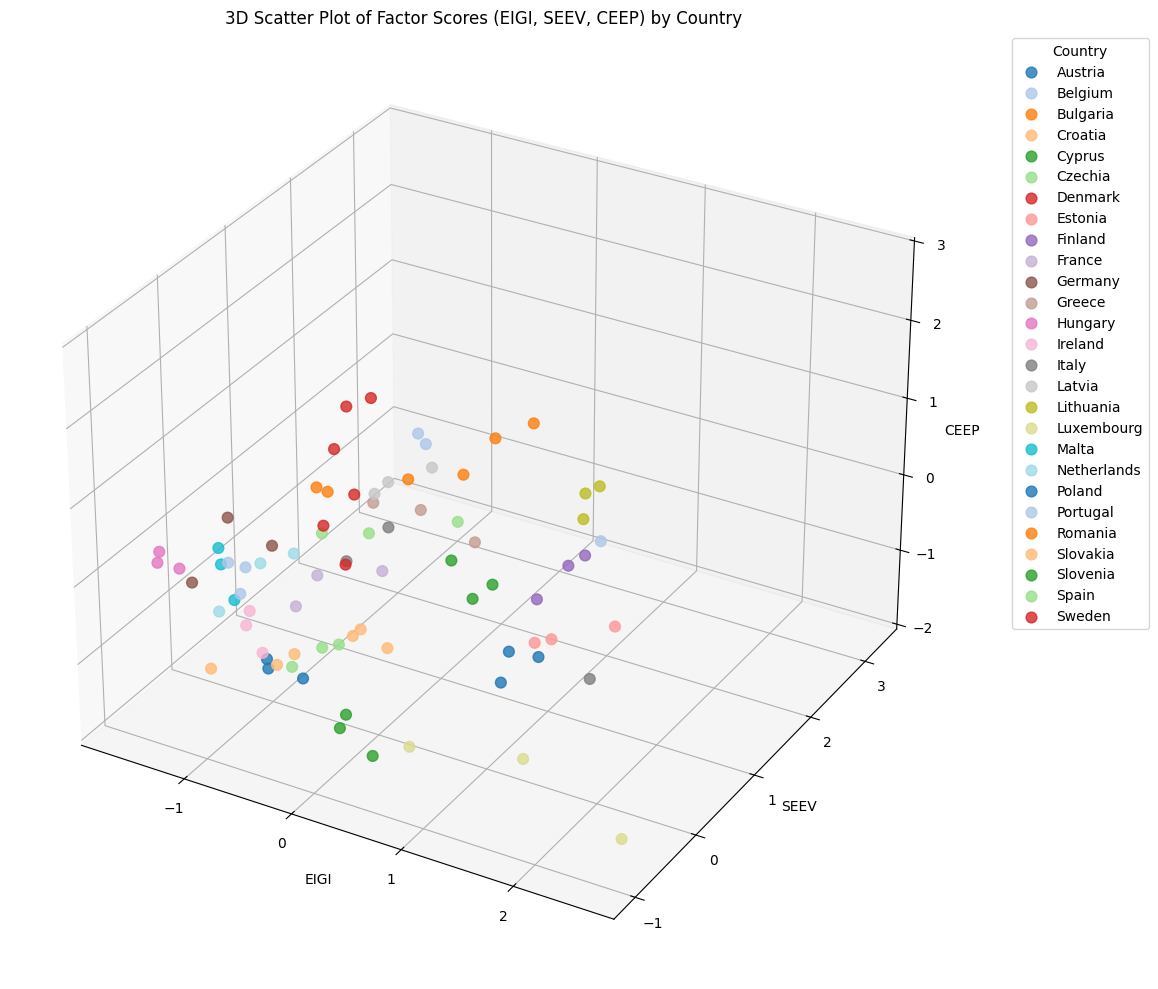

In [74]:
from mpl_toolkits.mplot3d import Axes3D

# Calculate factor scores for df_final
factor_scores = fa2.transform(df_final)
factor_scores_df_final = pd.DataFrame(factor_scores, columns=['F1', 'F2', 'F3'])
factor_scores_df_final['Country'] = df['ID'].str.split('_').str[0]

# Create 3D plot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Color palette for countries
unique_countries = factor_scores_df_final['Country'].unique()
palette = sns.color_palette('tab20', n_colors=len(unique_countries))
country_color_map = {country: palette[i] for i, country in enumerate(unique_countries)}

# Plot scatter points for each country
for country in unique_countries:
    country_data = factor_scores_df_final[factor_scores_df_final['Country'] == country]
    ax.scatter(country_data['F1'], country_data['F2'], country_data['F3'],
               color=country_color_map[country], label=country, s=60, alpha=0.8)

ax.set_title('3D Scatter Plot of Factor Scores (EIGI, SEEV, CEEP) by Country')
ax.set_xlabel('EIGI')
ax.set_ylabel('SEEV')
ax.set_zlabel('CEEP')
ax.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

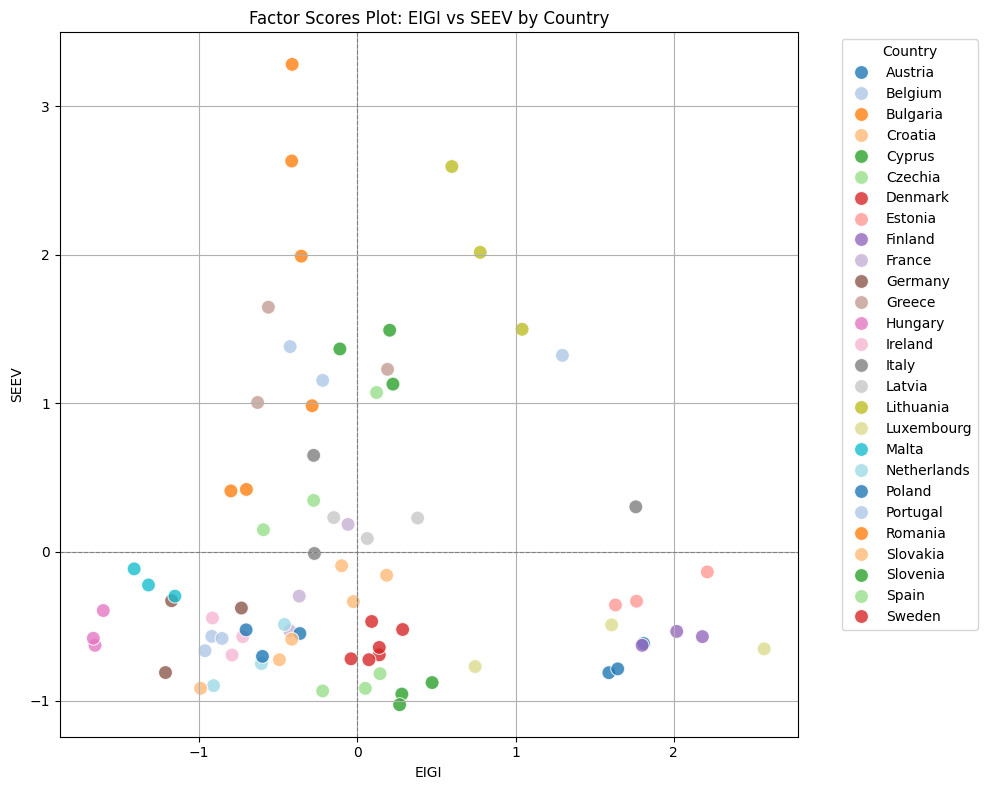

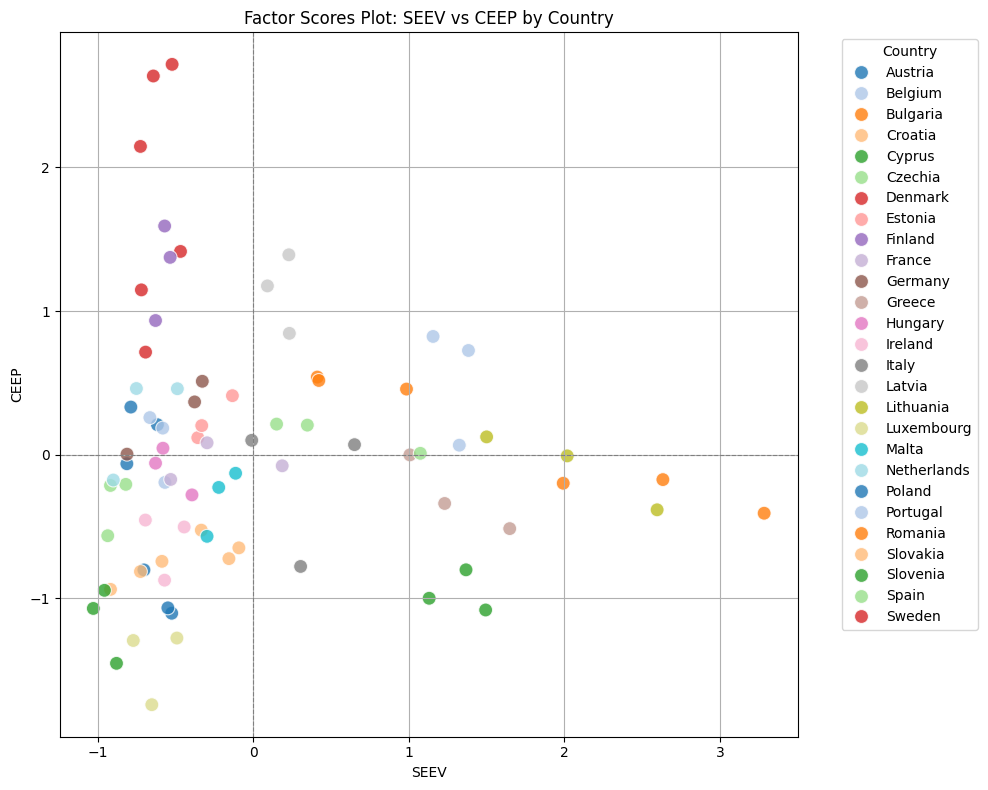

In [75]:
# Plot F1 vs F2
plt.figure(figsize=(10, 8))
sns.scatterplot(data=factor_scores_df_final, x='F1', y='F2', hue='Country', palette='tab20', s=100, alpha=0.8)
plt.title('Factor Scores Plot: EIGI vs SEEV by Country')
plt.xlabel('EIGI')
plt.ylabel('SEEV')
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')
plt.grid(True)
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Plot F2 vs F3
plt.figure(figsize=(10, 8))
sns.scatterplot(data=factor_scores_df_final, x='F2', y='F3', hue='Country', palette='tab20', s=100, alpha=0.8)
plt.title('Factor Scores Plot: SEEV vs CEEP by Country')
plt.xlabel('SEEV')
plt.ylabel('CEEP')
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')
plt.grid(True)
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

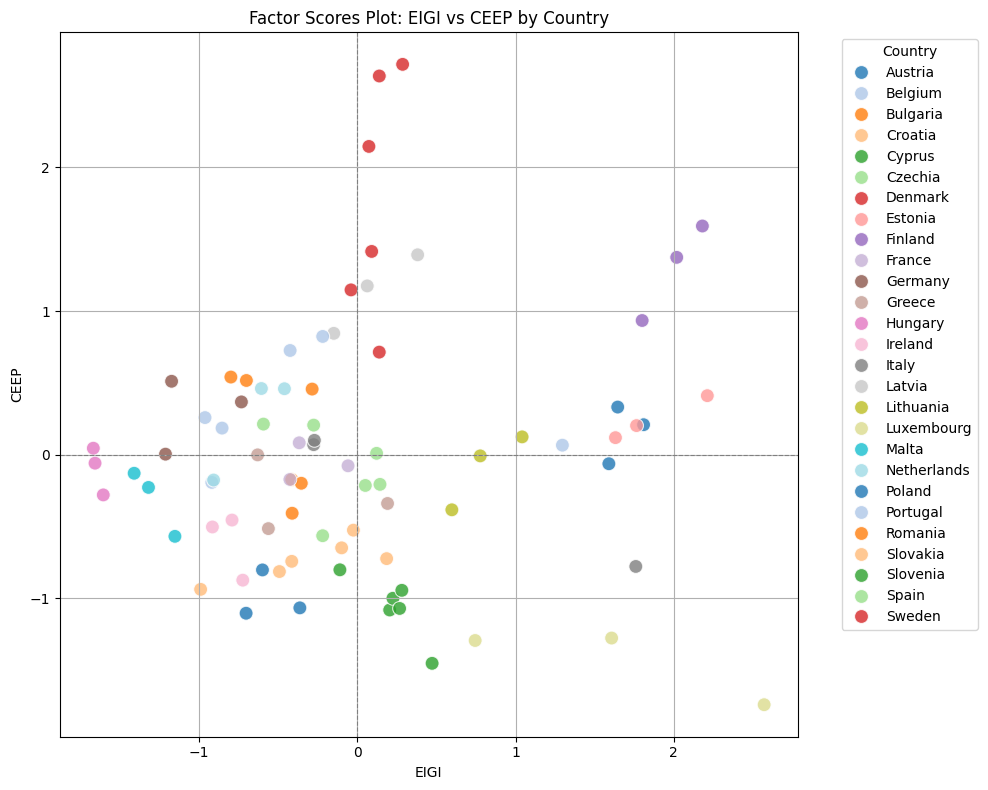

In [76]:
# Plot F1 vs F3
plt.figure(figsize=(10, 8))
sns.scatterplot(data=factor_scores_df_final, x='F1', y='F3', hue='Country', palette='tab20', s=100, alpha=0.8)
plt.title('Factor Scores Plot: EIGI vs CEEP by Country')
plt.xlabel('EIGI')
plt.ylabel('CEEP')
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')
plt.grid(True)
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [77]:
average_factor_scores = factor_scores_df_final.groupby('Country')[['F1', 'F2', 'F3']].mean()
average_factor_scores

,F1,F2,F3
Country,,,
Austria,1.681216,-0.738592,0.159160
Belgium,-0.912286,-0.604834,0.083608
Bulgaria,-0.393592,2.635743,-0.259811
Croatia,0.020373,-0.194492,-0.632297
Cyprus,0.106394,1.330132,-0.960411
Czechia,-0.008500,-0.890964,-0.328121
Denmark,0.063074,-0.626522,1.091978
Estonia,1.868950,-0.274113,0.244041
Finland,1.999428,-0.577559,1.299824


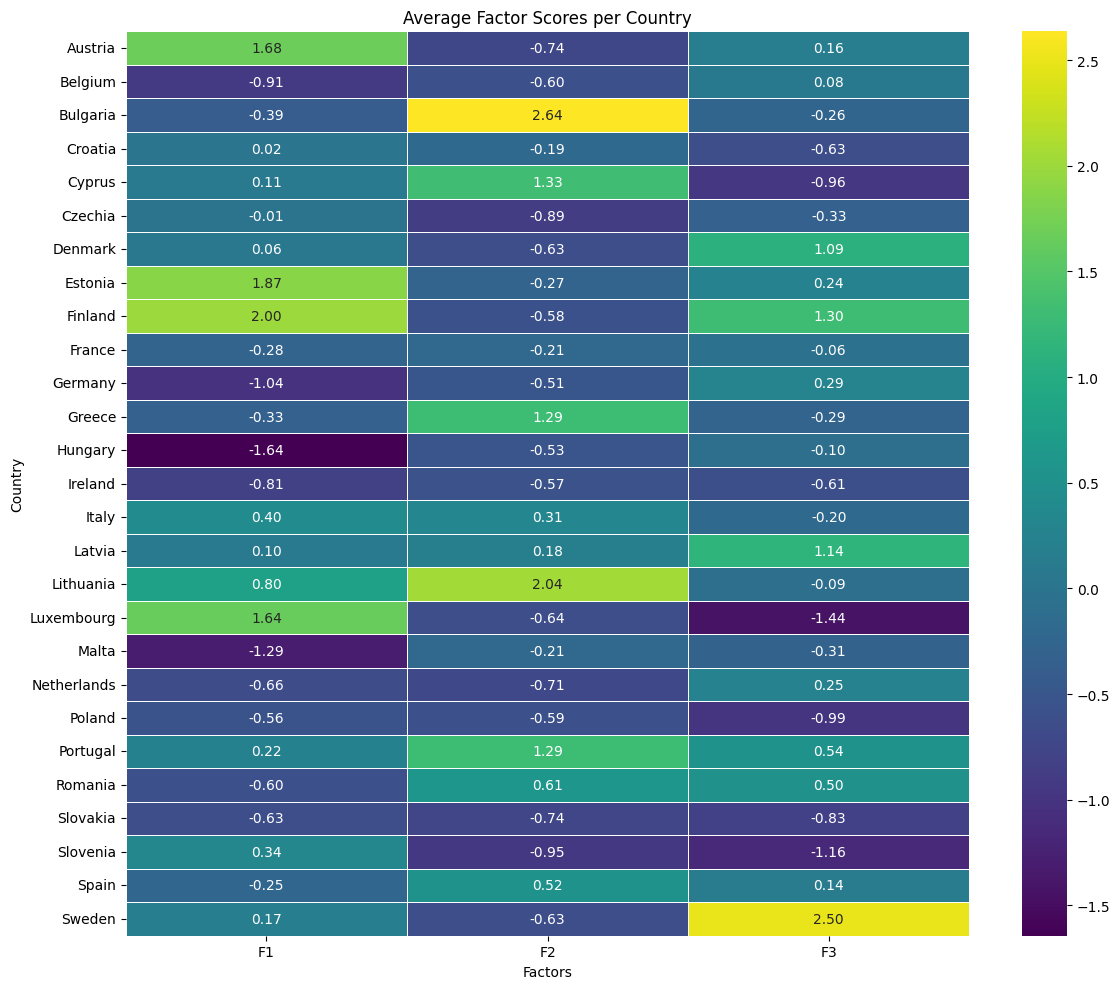

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))
sns.heatmap(average_factor_scores, annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Average Factor Scores per Country')
plt.xlabel('Factors')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

In [79]:
dominant_factors_data = []

# Calculate factor scores with original IDs
factor_scores = fa2.transform(df_final)
factor_scores_df_final_with_id = pd.DataFrame(factor_scores, columns=['F1', 'F2', 'F3'])
factor_scores_df_final_with_id['ID'] = df['ID']
factor_scores_df_final_with_id['Country'] = df['ID'].str.split('_').str[0]

for index, row in factor_scores_df_final_with_id.iterrows():
    scores = row[['F1', 'F2', 'F3']]
    abs_scores = scores.abs()
    dominant_factor = abs_scores.idxmax()
    dominant_factor_score = scores[dominant_factor]

    dominant_factors_data.append({
        'ID': row['ID'],
        'Country': row['Country'],
        'Dominant Factor': dominant_factor,
        'Dominant Factor Score': dominant_factor_score
    })

dominant_factors_df = pd.DataFrame(dominant_factors_data)
display(dominant_factors_df)

c:\Users\Pedro Salgado\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,ID,Country,Dominant Factor,Dominant Factor Score
0,Austria_2018,Austria,F1,1.589466
1,Austria_2020,Austria,F1,1.645349
2,Austria_2022,Austria,F1,1.808833
3,Belgium_2018,Belgium,F1,-0.919434
4,Belgium_2020,Belgium,F1,-0.962587
...,...,...,...,...
76,Spain_2020,Spain,F2,0.347285
77,Spain_2022,Spain,F2,1.073335
78,Sweden_2018,Sweden,F3,2.145687
79,Sweden_2020,Sweden,F3,2.635921


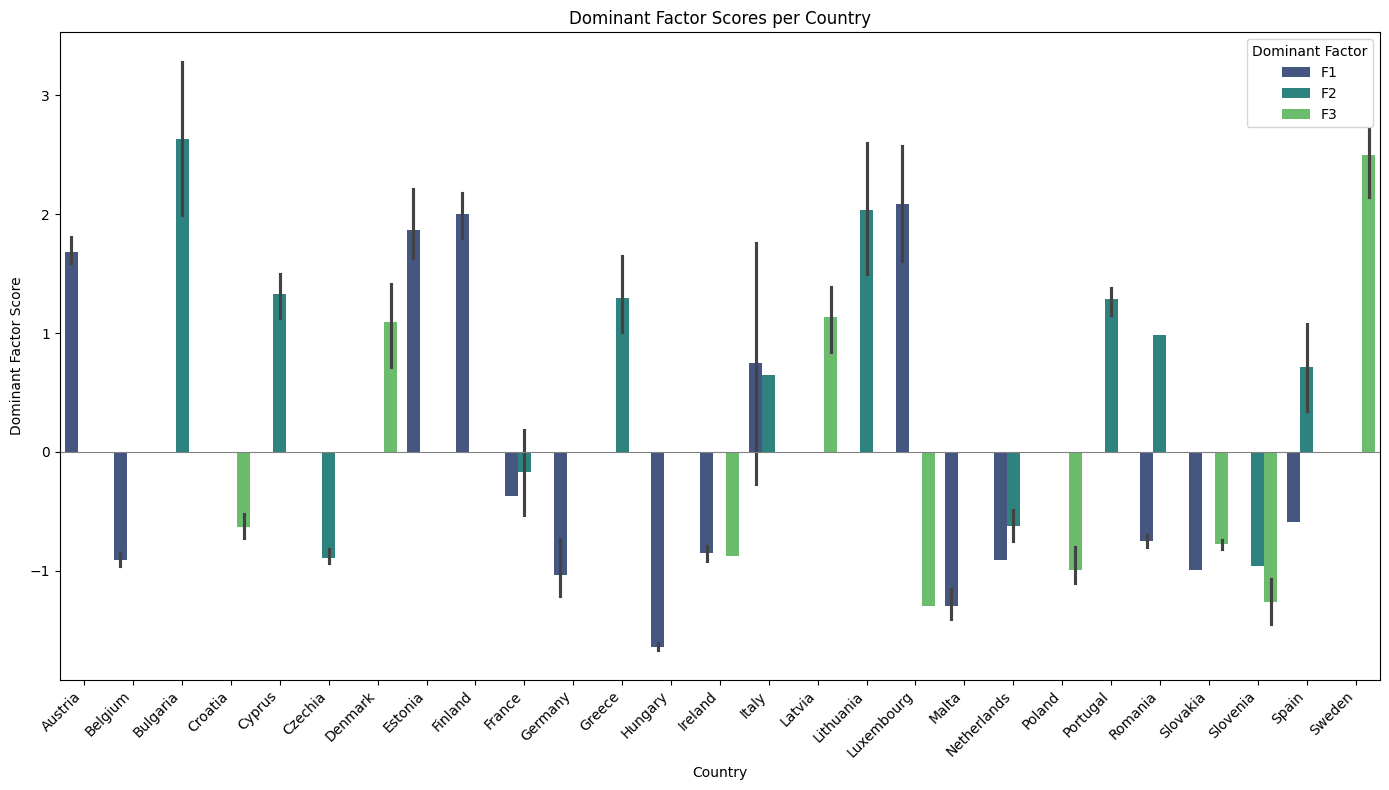

In [80]:
plt.figure(figsize=(14, 8))
sns.barplot(x='Country', y='Dominant Factor Score', hue='Dominant Factor', data=dominant_factors_df, palette='viridis')
plt.title('Dominant Factor Scores per Country')
plt.xlabel('Country')
plt.ylabel('Dominant Factor Score')
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='grey', linewidth=0.8)
plt.legend(title='Dominant Factor')
plt.tight_layout()
plt.show()

In [81]:
display(average_factor_scores)

,F1,F2,F3
Country,,,
Austria,1.681216,-0.738592,0.159160
Belgium,-0.912286,-0.604834,0.083608
Bulgaria,-0.393592,2.635743,-0.259811
Croatia,0.020373,-0.194492,-0.632297
Cyprus,0.106394,1.330132,-0.960411
Czechia,-0.008500,-0.890964,-0.328121
Denmark,0.063074,-0.626522,1.091978
Estonia,1.868950,-0.274113,0.244041
Finland,1.999428,-0.577559,1.299824


In [82]:
yearly_output_filename = 'yearly_country_factor_scores.csv'

# Export DataFrame to CSV
factor_scores_df_final_with_id.to_csv(yearly_output_filename, index=False)

print(f"Yearly factor scores DataFrame successfully exported to '{yearly_output_filename}'")

Yearly factor scores DataFrame successfully exported to 'yearly_country_factor_scores.csv'


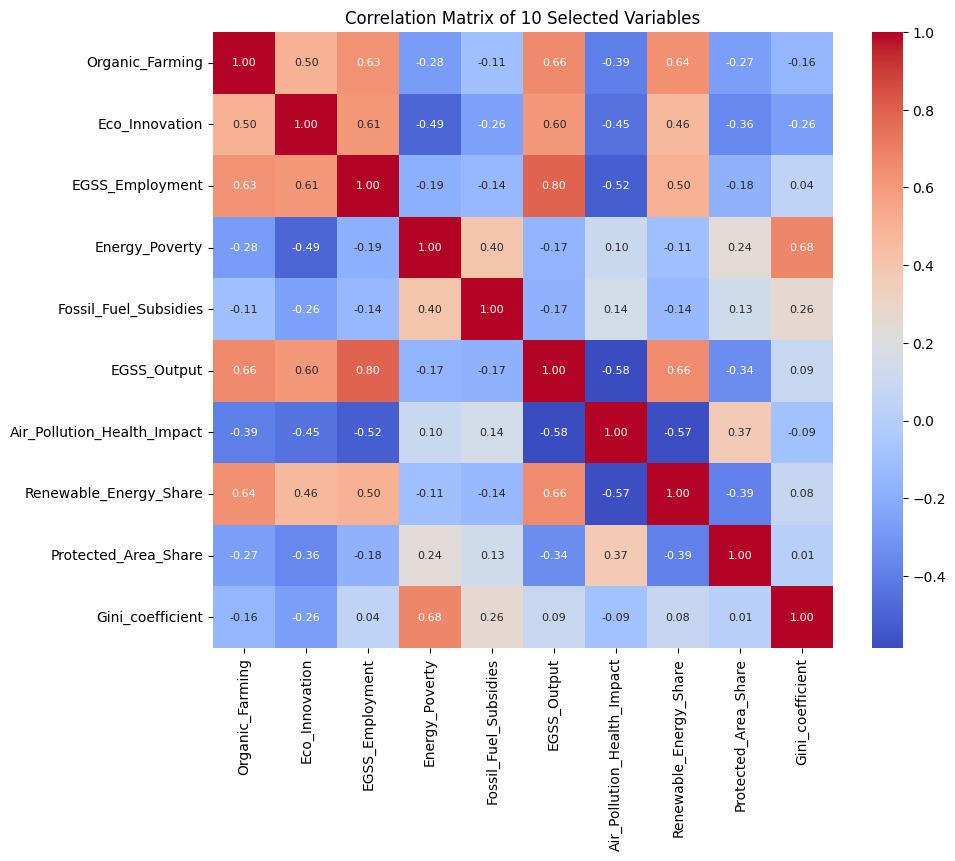

In [83]:
newcorr_matrixtest = df_scaled.corr()

plt.figure(figsize=(10, 8)) 
sns.heatmap(newcorr_matrixtest, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 8}) 
plt.title('Correlation Matrix of 10 Selected Variables')
plt.show()

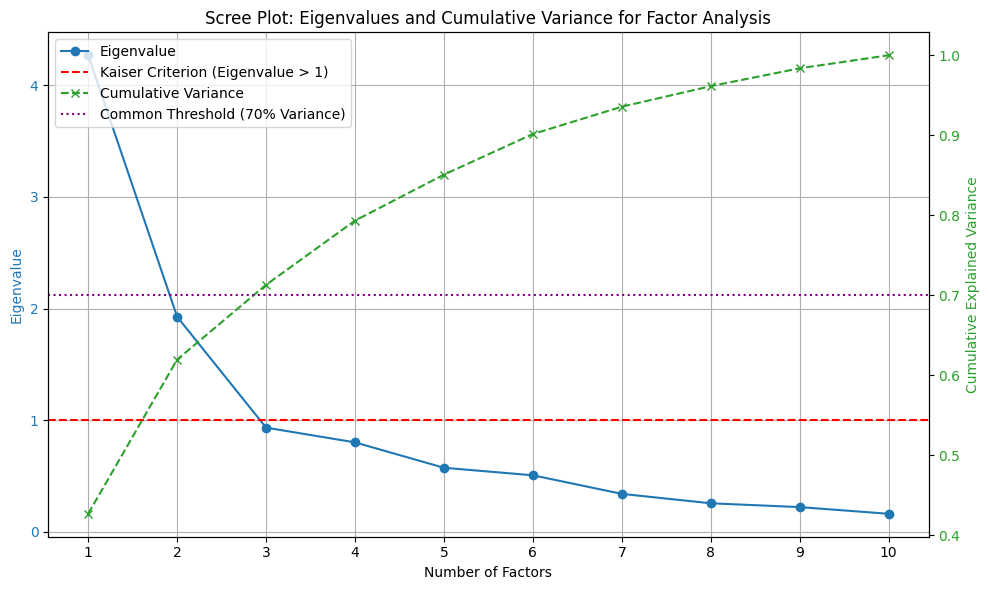

In [84]:
import matplotlib.pyplot as plt
import numpy as np


fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Eigenvalues on the primary y-axis
color = 'tab:blue'
ax1.set_xlabel('Number of Factors')
ax1.set_ylabel('Eigenvalue', color=color)
ax1.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='-', color=color, label='Eigenvalue')
ax1.tick_params(axis='y', labelcolor=color)
ax1.axhline(y=1, color='red', linestyle='--', label='Kaiser Criterion (Eigenvalue > 1)')

# Create a secondary y-axis for Cumulative Variance
ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Cumulative Explained Variance', color=color)
ax2.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='x', linestyle='--', color=color, label='Cumulative Variance')
ax2.tick_params(axis='y', labelcolor=color)
ax2.axhline(y=0.7, color='purple', linestyle=':', label='Common Threshold (70% Variance)')

plt.title('Scree Plot: Eigenvalues and Cumulative Variance for Factor Analysis')
ax1.grid(True)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.xticks(range(1, len(eigenvalues) + 1))
plt.tight_layout()
plt.show()